# Water quality diagnosis — KVP site (Environment Agency data, 2004–2013)

**Purpose.** Editable, reproducible diagnosis of the water quality at one monitoring site, built from the
publicly available Environment Agency (EA) water-quality record supplied as
`data/KVP_WQ_dataset_2004-2013.csv`.

**How the notebook is organised**

| § | Content |
|---|---|
| 1 | Set-up and **configuration** (everything you are expected to edit lives here) |
| 2 | Data loading and cleaning (censored "`<`" results, qualitative results) |
| 3 | Site description and data inventory (what was measured, when, how often) |
| 4 | Summary statistics |
| 5 | Time series |
| 6 | Seasonality |
| 7 | Inter-annual variability and monotonic trends |
| 8 | Oxygen regime |
| 9 | Nutrients, chlorophyll-a and trophic state |
| 10 | Relationships between variables |
| 11 | Comparison with reference values (template — **off by default**, see note there) |
| 12 | **Meteorological characterisation** (placeholder — activates when a met file is configured) |
| 13 | **Water quality × meteorology** (placeholder — activates with §12) |
| 14 | Headline figures and space for the written diagnosis |

**Things to keep in mind when reading the outputs**

* Every number in the tables and figures is computed from the CSV by the code in this notebook; nothing is typed in by hand.
* The file contains a single sampling point whose EA label is *"BURGHFIELD SAILING CLUB AT BURGHFIELD LAKE, THEALE"*, EA type
  *"FRESHWATER - LAKES/PONDS/RESERVOIRS"*. The EA type does not distinguish reservoirs from lakes/ponds, so
  **whether the water body is a reservoir in the strict sense is not something this dataset can confirm**.
* One sampling point, sampled roughly monthly, represents the lake **at that point and at the sampling time only**
  (the file holds no sampling-depth field; near-surface shore/jetty sampling is likely but **not stated in the data**).
* Many results are reported as below a detection limit (`<x`). How these are handled is a choice (see §1 and §2) and
  it matters for some determinands (e.g. orthophosphate, ammonia, metals).
* Reference/standard values and trophic boundaries were written **from memory and could not be checked against the
  original sources from the environment in which this notebook was prepared**. They are isolated in the
  configuration cell and flagged where used. Please verify them before relying on them.

## 1. Set-up and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import stats
from IPython.display import display

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)

pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


In [2]:
# =============================================================================
# CONFIGURATION — edit here
# =============================================================================

# ---- Files -------------------------------------------------------------------
DATA_DIR = Path("data")
WQ_FILE = DATA_DIR / "KVP_WQ_dataset_2004-2013.csv"
SITE_ID = None            # EA sampling-point notation; None = the file must contain exactly one site
SITE_SHORT_NAME = "KVP"   # used in figure titles and output file names only

SAVE_OUTPUTS = False      # True -> figures (PNG) and tables (CSV) are also written to OUTPUT_DIR
OUTPUT_DIR = Path("outputs")
FIG_DPI = 200

# ---- Results below the detection limit ("<x") ---------------------------------
# Value used in statistics for censored results:
#   "half" -> x/2 (default) | "lod" -> x | "zero" -> 0
# Whatever is chosen, the summary table also reports the lower/upper bounds of the mean
# (censored = 0 and censored = x), and medians that fall below the limit are shown as "<x".
CENSORED_SUBSTITUTION = "half"

# ---- Seasons (month -> season) -------------------------------------------------
SEASONS = {12: "Winter (DJF)", 1: "Winter (DJF)", 2: "Winter (DJF)",
           3: "Spring (MAM)", 4: "Spring (MAM)", 5: "Spring (MAM)",
           6: "Summer (JJA)", 7: "Summer (JJA)", 8: "Summer (JJA)",
           9: "Autumn (SON)", 10: "Autumn (SON)", 11: "Autumn (SON)"}
SEASON_ORDER = ["Winter (DJF)", "Spring (MAM)", "Summer (JJA)", "Autumn (SON)"]

# ---- Variable catalogue --------------------------------------------------------
# EA determinand code -> short key, label, unit for display, thematic group.
# Determinands present in the file but not listed here are reported in the inventory (§3)
# and otherwise ignored. `factor` converts the unit in the file to the display unit.
VARIABLES = {
    76:   dict(key="temp",     label="Water temperature",               unit="°C",          group="Physical"),
    61:   dict(key="ph",       label="pH",                              unit="pH units",    group="Physical"),
    77:   dict(key="cond25",   label="Conductivity at 25 °C",           unit="µS/cm",       group="Physical"),
    62:   dict(key="cond20",   label="Conductivity at 20 °C",           unit="µS/cm",       group="Physical"),
    162:  dict(key="alk",      label="Alkalinity to pH 4.5",            unit="mg/L CaCO3",  group="Physical"),
    135:  dict(key="ss",       label="Suspended solids (105 °C)",       unit="mg/L",        group="Physical"),
    72:   dict(key="colour",   label="Colour, filtered",                unit="colour units as reported", group="Physical"),
    9924: dict(key="do",       label="Dissolved oxygen",                unit="mg/L O2",     group="Oxygen and organic matter"),
    9901: dict(key="do_sat",   label="Dissolved oxygen saturation",     unit="%",           group="Oxygen and organic matter"),
    85:   dict(key="bod",      label="BOD, 5-day ATU",                  unit="mg/L O2",     group="Oxygen and organic matter"),
    111:  dict(key="nh4_n",    label="Ammoniacal nitrogen",             unit="mg/L N",      group="Nitrogen"),
    119:  dict(key="nh3_n",    label="Un-ionised ammonia",              unit="mg/L N",      group="Nitrogen"),
    118:  dict(key="no2_n",    label="Nitrite",                         unit="mg/L N",      group="Nitrogen"),
    117:  dict(key="no3_n",    label="Nitrate",                         unit="mg/L N",      group="Nitrogen"),
    116:  dict(key="ton_n",    label="Total oxidised nitrogen",         unit="mg/L N",      group="Nitrogen"),
    9943: dict(key="ton_f_n",  label="Total oxidised nitrogen, filtered", unit="mg/L N",    group="Nitrogen"),
    9686: dict(key="tn",       label="Total nitrogen",                  unit="mg/L N",      group="Nitrogen"),
    348:  dict(key="tp",       label="Total phosphorus",                unit="µg/L P",      group="Phosphorus and algae", factor=1000.0),
    180:  dict(key="srp",      label="Orthophosphate, reactive",        unit="µg/L P",      group="Phosphorus and algae", factor=1000.0),
    7887: dict(key="chla",     label="Chlorophyll (acetone extract)",   unit="µg/L",        group="Phosphorus and algae"),
    6450: dict(key="cu_diss",  label="Copper, dissolved",               unit="µg/L",        group="Metals"),
    6455: dict(key="zn",       label="Zinc",                            unit="µg/L",        group="Metals"),
}
GROUP_ORDER = ["Physical", "Oxygen and organic matter", "Nitrogen", "Phosphorus and algae", "Metals"]

# ---- Analysis settings ---------------------------------------------------------
LONG_RECORD_MIN_YEARS = 8     # variables with at least this many calendar years are used for §7
TREND_MAX_CENSORED = 0.50     # variables with a larger censored fraction are not trend-tested
TREND_ALPHA = 0.05
CORR_MIN_N = 20               # minimum number of paired samples to report a correlation
CORR_MAX_CENSORED = 0.50
DO_SAT_BINS = [0, 60, 80, 100, 120, np.inf]   # descriptive bins for O2 saturation (%), NOT standards

# ---- Trophic-state boundaries (§9) ---------------------------------------------
# !! Written from memory of the OECD (1982) fixed-boundary scheme (Vollenweider & Kerekes).
# !! NOT checked against the original report here -> verify before use, then set to True.
TROPHIC_BOUNDARIES_VERIFIED = False
TROPHIC_CLASSES = ["ultra-oligotrophic", "oligotrophic", "mesotrophic", "eutrophic", "hypertrophic"]
TROPHIC_BOUNDARIES = {            # upper limits of the first four classes
    "tp_mean":   [4.0, 10.0, 35.0, 100.0],   # annual mean total P, µg/L
    "chla_mean": [1.0, 2.5, 8.0, 25.0],      # annual mean chlorophyll-a, µg/L
    "chla_max":  [2.5, 8.0, 25.0, 75.0],     # annual maximum chlorophyll-a, µg/L
}

# ---- Reference values (§11) ----------------------------------------------------
# !! TEMPLATE. The determinand suite and the sampling purpose in the file ("ENVIRONMENTAL MONITORING
# !! STATUTORY (EU DIRECTIVES)") suggest Freshwater Fish Directive monitoring — this is an inference,
# !! not something stated in the file. The values below are the *cyprinid-water* values of that
# !! directive as recalled from memory; the designation of this water (salmonid/cyprinid, if any)
# !! is unknown to me. Nothing here was checked against the legal text.
# !! Each entry is used only if verified=True, or if SHOW_UNVERIFIED_REFERENCE_VALUES is True.
# kind: "max" (value should not be exceeded), "min", or "range" (value = (low, high)).
# `factor` converts the value as written in the source to the unit used in this notebook.
SHOW_UNVERIFIED_REFERENCE_VALUES = False
N_PER_NH3, N_PER_NH4, N_PER_NO2 = 14.007 / 17.031, 14.007 / 18.039, 14.007 / 46.005   # mass of N per mass of species
REFERENCE_VALUES = [
    dict(key="ph",      kind="range", value=(6.0, 9.0), factor=1.0,       label="pH 6–9 (I)",                         source="FFD cyprinid, from memory", verified=False),
    dict(key="do",      kind="min",   value=7.0,        factor=1.0,       label="DO 7 mg/L (I; rule is '50 % of samples ≥ 7')", source="FFD cyprinid, from memory", verified=False),
    dict(key="temp",    kind="max",   value=28.0,       factor=1.0,       label="Temperature 28 °C (I)",              source="FFD cyprinid, from memory", verified=False),
    dict(key="nh3_n",   kind="max",   value=0.025,      factor=N_PER_NH3, label="Un-ionised ammonia 0.025 mg/L NH3 (I)", source="FFD, from memory",       verified=False),
    dict(key="nh4_n",   kind="max",   value=1.0,        factor=N_PER_NH4, label="Total ammonium 1 mg/L NH4 (I)",      source="FFD, from memory",          verified=False),
    dict(key="no2_n",   kind="max",   value=0.03,       factor=N_PER_NO2, label="Nitrite 0.03 mg/L NO2 (G)",          source="FFD cyprinid, from memory", verified=False),
    dict(key="ss",      kind="max",   value=25.0,       factor=1.0,       label="Suspended solids 25 mg/L (G)",       source="FFD, from memory",          verified=False),
    dict(key="bod",     kind="max",   value=6.0,        factor=1.0,       label="BOD5 6 mg/L (G)",                    source="FFD cyprinid, from memory", verified=False),
    dict(key="zn",      kind="max",   value=1.0,        factor=1000.0,    label="Total zinc 1.0 mg/L (I, hardness 100 mg/L CaCO3)", source="FFD cyprinid, from memory", verified=False),
    dict(key="cu_diss", kind="max",   value=0.04,       factor=1000.0,    label="Dissolved copper 0.04 mg/L (G, hardness 100 mg/L CaCO3)", source="FFD, from memory", verified=False),
]

# ---- Meteorology (§12–13) — leave MET_FILE = None until the met data are ready -------
# Expected file: CSV with one datetime column and one column per variable (any regular or
# irregular time step; it is aggregated to daily values with the `agg` given per variable).
MET_FILE = None                      # e.g. DATA_DIR / "KVP_met.csv"
MET_DATETIME_COL = "datetime"
MET_VARIABLES = {
    # "column name in file": dict(label="Air temperature", unit="°C",  agg="mean"),
    # "column name in file": dict(label="Precipitation",   unit="mm",  agg="sum"),
    # "column name in file": dict(label="Wind speed",      unit="m/s", agg="mean"),
    # "column name in file": dict(label="Solar radiation", unit="W/m²", agg="mean"),
}
ANTECEDENT_WINDOWS_DAYS = (1, 7, 30)  # windows ending on each WQ sampling day, used in §13

# ---- Figure style --------------------------------------------------------------
C_SERIES, C_SERIES_LIGHT, C_INK, C_INK2, C_MUTED = "#2a78d6", "#b7d3f6", "#0b0b0b", "#52514e", "#898781"
C_ACCENT, C_GRID, C_AXIS, C_SURFACE = "#eb6834", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": C_SURFACE, "axes.facecolor": C_SURFACE, "savefig.facecolor": C_SURFACE,
    "figure.dpi": 110, "savefig.dpi": FIG_DPI, "savefig.bbox": "tight",
    "axes.edgecolor": C_AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.titlecolor": C_INK,
    "axes.labelsize": 9, "axes.labelcolor": C_INK2, "text.color": C_INK,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "xtick.labelcolor": C_INK2, "ytick.labelcolor": C_INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False, "legend.fontsize": 8.5,
    "figure.titlesize": 12, "figure.titleweight": "bold", "font.size": 9,
})

## 2. Data loading and cleaning

The EA export is in *long* format (one row per sample × determinand). The loader:

* keeps the raw result string and splits it into a qualifier (`<`, `>` or none) and a numeric value;
* separates **qualitative** results (e.g. "Not found", "Normal") from numeric ones;
* maps determinand codes to the catalogue in §1 and applies unit factors (mg/L → µg/L for phosphorus);
* builds three aligned wide tables indexed by sampling date-time:
  `wq_rep` (values **as reported**, censored results at their detection limit), `wq_cens` (True where censored) and
  `wq_wide` (values **used in statistics**, after the substitution chosen in §1).

In [3]:
def load_ea_wq(path, site_id=None):
    # Read an Environment Agency water-quality export (long format) into a tidy table.
    raw = pd.read_csv(path, dtype=str)
    raw.columns = [c.strip() for c in raw.columns]
    sites = raw["samplingPoint.notation"].unique()
    if site_id is None:
        if len(sites) != 1:
            raise ValueError(f"File contains {len(sites)} sampling points {list(sites)}; set SITE_ID.")
        site_id = sites[0]
    raw = raw[raw["samplingPoint.notation"] == site_id].copy()

    df = pd.DataFrame({
        "datetime": pd.to_datetime(raw["phenomenonTime"]),
        "det_code": raw["determinand.notation"].astype(int),
        "det_label": raw["determinand.prefLabel"],
        "result_raw": raw["result"].str.strip(),
        "unit_raw": raw["unit"],
        "purpose": raw["samplingPurpose"],
        "material": raw["sampleMaterialType"],
    })
    parts = df["result_raw"].str.extract(r"^([<>]?)\s*(.*)$")
    df["qualifier"] = parts[0]
    df["value_raw"] = pd.to_numeric(parts[1], errors="coerce")
    df["is_numeric"] = df["value_raw"].notna()
    df["censored"] = df["qualifier"].eq("<") & df["is_numeric"]
    site_cols = [c for c in raw.columns if c.startswith("samplingPoint.")]
    site_meta = raw[site_cols].drop_duplicates().T
    return df.sort_values(["datetime", "det_code"]).reset_index(drop=True), site_meta


obs_all, site_meta = load_ea_wq(WQ_FILE, SITE_ID)

# ---- attach catalogue information and build the analysis table --------------------
cat = pd.DataFrame.from_dict(VARIABLES, orient="index").rename_axis("det_code").reset_index()
if "factor" not in cat:
    cat["factor"] = 1.0
cat["factor"] = cat["factor"].fillna(1.0)
META = {r.key: dict(label=r.label, unit=r.unit, group=r.group, det_code=r.det_code) for r in cat.itertuples()}

wq = obs_all[obs_all["is_numeric"]].merge(cat, on="det_code", how="inner")
wq["value"] = wq["value_raw"] * wq["factor"]                     # as reported (LOD if censored), display unit
sub = {"half": 0.5, "lod": 1.0, "zero": 0.0}[CENSORED_SUBSTITUTION]
wq["value_stat"] = np.where(wq["censored"], wq["value"] * sub, wq["value"])
wq["year"] = wq["datetime"].dt.year
wq["month"] = wq["datetime"].dt.month
wq["season"] = pd.Categorical(wq["month"].map(SEASONS), categories=SEASON_ORDER, ordered=True)

n_gt = int((wq["qualifier"] == ">").sum())
if n_gt:
    print(f"WARNING: {n_gt} results carry a '>' qualifier; they are used at face value.")
dups = wq.duplicated(["datetime", "key"]).sum()
if dups:
    print(f"WARNING: {dups} duplicated datetime × determinand rows; wide tables use their mean.")

KEYS = [k for k in META if k in set(wq["key"])]                  # catalogue order, present in file
wq_rep = wq.pivot_table(index="datetime", columns="key", values="value", aggfunc="mean").reindex(columns=KEYS)
wq_wide = wq.pivot_table(index="datetime", columns="key", values="value_stat", aggfunc="mean").reindex(columns=KEYS)
wq_cens = (wq.pivot_table(index="datetime", columns="key", values="censored", aggfunc="max")
             .reindex(columns=KEYS).fillna(0).astype(bool))

qual = obs_all[~obs_all["is_numeric"]].copy()                     # qualitative results

print(f"Rows in file (this site): {len(obs_all)}")
print(f"  numeric results used in the analysis : {len(wq)}  ({wq['key'].nunique()} determinands)")
print(f"  qualitative results                   : {len(qual)}")
print(f"  numeric results not in the catalogue  : {int(obs_all['is_numeric'].sum()) - len(wq)}")
print(f"Sampling visits: {wq_wide.shape[0]}, from {wq_wide.index.min():%Y-%m-%d} to {wq_wide.index.max():%Y-%m-%d}")
print(f"Censored ('<') results: {int(wq['censored'].sum())} of {len(wq)} numeric results "
      f"({100 * wq['censored'].mean():.1f} %); substitution for statistics: '{CENSORED_SUBSTITUTION}'")


# ---- small helpers used throughout -----------------------------------------------
def sig(x, n=3):
    # Format a number to n significant figures ('' for missing).
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return ""
    return f"{x:.0f}" if abs(x) >= 10 ** n else f"{x:.{n}g}"


def q_cens(values, censored, p=0.5):
    # Rank-based (nearest-rank) quantile of reported values; prefixed with '<' if that result is censored.
    # p = 0.5 gives the conventional median (mean of the two middle results when n is even); if either
    # middle result is censored the median is reported as '<' the upper of the two.
    v, c = np.asarray(values, float), np.asarray(censored, bool)
    ok = np.isfinite(v)
    v, c = v[ok], c[ok]
    if not len(v):
        return ""
    o = np.lexsort((~c, v))            # ascending value; at equal value '<x' ranks below 'x'
    v, c = v[o], c[o]
    if p == 0.5 and len(v) % 2 == 0:
        a, b = len(v) // 2 - 1, len(v) // 2
        return "<" + sig(v[b]) if (c[a] or c[b]) else sig((v[a] + v[b]) / 2)
    i = min(len(v) - 1, max(0, int(np.ceil(p * len(v))) - 1))
    return ("<" if c[i] else "") + sig(v[i])


def figure_header(fig, title=None, handles=None, ncols=3):
    # Title (left) and legend (right) in a fixed-height band above the panels, then tight layout below it.
    h = fig.get_figheight()
    if title:
        fig.suptitle(title, x=0.01, y=1 - 0.10 / h, ha="left", va="top")
    if handles:
        fig.legend(handles=handles, loc="upper right", ncols=ncols, bbox_to_anchor=(0.995, 1 - 0.04 / h))
    band = 0.28 if (title or handles) else 0.0
    fig.tight_layout(rect=(0, 0, 1, 1 - band / h))


def ax_label(meta, key):
    m = meta[key]
    return f"{m['label']} [{m['unit']}]"


def finish(fig, name):
    # Show the figure and optionally save it.
    if SAVE_OUTPUTS:
        (OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / "figures" / f"{SITE_SHORT_NAME}_{name}.png")
    plt.show()


def show_table(df, name, index=True):
    # Display a table and optionally save it as CSV.
    if SAVE_OUTPUTS:
        (OUTPUT_DIR / "tables").mkdir(parents=True, exist_ok=True)
        df.to_csv(OUTPUT_DIR / "tables" / f"{SITE_SHORT_NAME}_{name}.csv", index=index)
    display(df)

Rows in file (this site): 1726
  numeric results used in the analysis : 1469  (22 determinands)
  qualitative results                   : 256
  numeric results not in the catalogue  : 1
Sampling visits: 110, from 2004-04-26 to 2013-12-02
Censored ('<') results: 467 of 1469 numeric results (31.8 %); substitution for statistics: 'half'


## 3. Site description and data inventory

### 3.1 Sampling point (as described in the file)

In [4]:
site_table = site_meta.copy()
site_table.index = site_table.index.str.replace("samplingPoint.", "", regex=False)
site_table.columns = ["value"] if site_table.shape[1] == 1 else [f"value_{i}" for i in range(site_table.shape[1])]
extra = pd.DataFrame({"value": [" | ".join(sorted(obs_all["purpose"].unique())),
                                " | ".join(sorted(obs_all["material"].unique())),
                                str(WQ_FILE)]},
                     index=["samplingPurpose", "sampleMaterialType", "source file"])
site_table = pd.concat([site_table, extra]) if site_table.shape[1] == 1 else site_table
show_table(site_table, "site_metadata")

,value
notation,TH-PGWL0165
prefLabel,"BURGHFIELD SAILING CLUB AT BURGHFIELD LAKE, TH..."
longitude,-1.0656
latitude,51.4279
region,Thames
area,THAMES - WEST THAMES
subArea,Multiple Values
samplingPointStatus,CLOSED
samplingPointType,FRESHWATER - LAKES/PONDS/RESERVOIRS
samplingPurpose,ENVIRONMENTAL MONITORING STATUTORY (EU DIRECTI...


### 3.2 What was measured, when, and how often

The inventory lists **every** determinand in the file, including those not used further. The heat map shows the number
of results per determinand and calendar year — the record is not homogeneous: a core suite covers the whole period,
while nutrients, chlorophyll, alkalinity and conductivity cover only part of it. Statistics for different determinands
therefore describe **different periods**; this matters whenever two determinands are compared.

In [5]:
inv = (obs_all.groupby(["det_code", "det_label", "unit_raw"])
       .agg(n=("result_raw", "size"), first=("datetime", "min"), last=("datetime", "max"),
            n_censored=("censored", "sum"), numeric=("is_numeric", "all"))
       .reset_index())
inv["pct_censored"] = (100 * inv["n_censored"] / inv["n"]).round(1)
inv["first"] = inv["first"].dt.date
inv["last"] = inv["last"].dt.date
inv["key"] = inv["det_code"].map({v["det_code"]: k for k, v in META.items()})
inv["used"] = np.where(inv["key"].notna(), "analysed", np.where(inv["numeric"], "not in catalogue", "qualitative (§3.3)"))
order = {c: i for i, c in enumerate(VARIABLES)}
inv = inv.sort_values("det_code", key=lambda s: s.map(lambda c: order.get(c, 10_000 + c))).reset_index(drop=True)
inventory = inv[["det_code", "det_label", "unit_raw", "key", "used", "n", "first", "last", "n_censored", "pct_censored"]]
show_table(inventory, "inventory", index=False)

,det_code,det_label,unit_raw,key,used,n,first,last,n_censored,pct_censored
0,76,Temperature of Water,CELSIUS,temp,analysed,110,2004-04-26,2013-12-02,0,0.0
1,61,pH,PH UNITS,ph,analysed,110,2004-04-26,2013-12-02,0,0.0
2,77,Conductivity at 25 C,MICROSIEMENS PER CENTIMETRE,cond25,analysed,29,2007-11-16,2010-03-16,0,0.0
3,62,Conductivity at 20 C,MICROSIEMENS PER CENTIMETRE,cond20,analysed,7,2007-02-02,2007-10-19,0,0.0
4,162,Alkalinity to pH 4.5 as CaCO3,MILLIGRAM PER LITRE,alk,analysed,39,2006-12-21,2010-03-16,0,0.0
5,135,"Solids, Suspended at 105 C",MILLIGRAM PER LITRE,ss,analysed,110,2004-04-26,2013-12-02,34,30.9
6,72,"Colour, Filtered",COLOUR,colour,analysed,34,2007-05-31,2010-03-16,0,0.0
7,9924,"Oxygen, Dissolved as O2",MILLIGRAM PER LITRE,do,analysed,110,2004-04-26,2013-12-02,0,0.0
8,9901,"Oxygen, Dissolved, % Saturation",PERCENTAGE,do_sat,analysed,110,2004-04-26,2013-12-02,0,0.0
9,85,BOD : 5 Day ATU,MILLIGRAM PER LITRE,bod,analysed,37,2004-04-26,2007-11-16,5,13.5


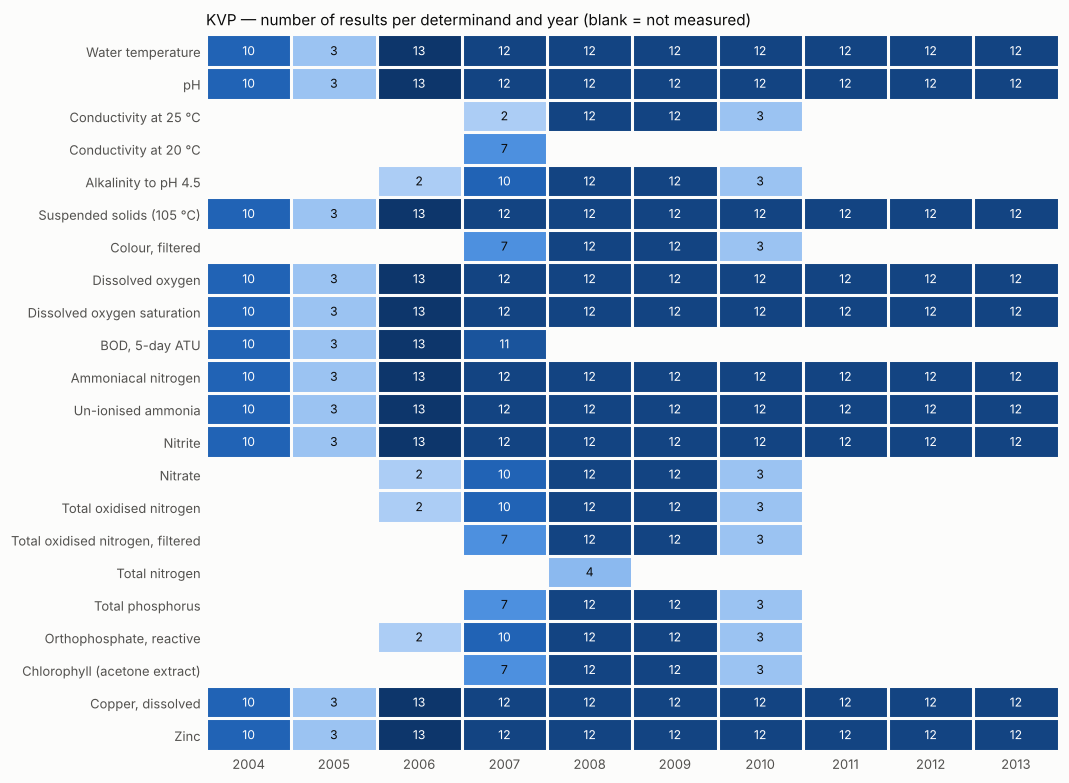

In [6]:
# Number of results per determinand and year (sequential single-hue scale; counts printed in the cells)
counts = (wq.assign(lab=wq["key"].map(lambda k: META[k]["label"]))
            .pivot_table(index="lab", columns="year", values="value", aggfunc="count")
            .reindex([META[k]["label"] for k in KEYS])
            .reindex(columns=range(wq["year"].min(), wq["year"].max() + 1)))
seq = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"])
seq.set_bad(C_SURFACE)

fig, ax = plt.subplots(figsize=(10, 0.33 * len(counts) + 1.2))
vmax = np.nanmax(counts.values)
ax.imshow(np.ma.masked_invalid(counts.values), aspect="auto", cmap=seq, vmin=0, vmax=vmax)
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        v = counts.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.55 * vmax else C_INK)
ax.set_xticks(range(counts.shape[1]), counts.columns)
ax.set_yticks(range(counts.shape[0]), counts.index)
ax.set_xticks(np.arange(-.5, counts.shape[1]), minor=True)
ax.set_yticks(np.arange(-.5, counts.shape[0]), minor=True)
ax.grid(False)
ax.grid(which="minor", color=C_SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"{SITE_SHORT_NAME} — number of results per determinand and year (blank = not measured)")
finish(fig, "coverage_heatmap")

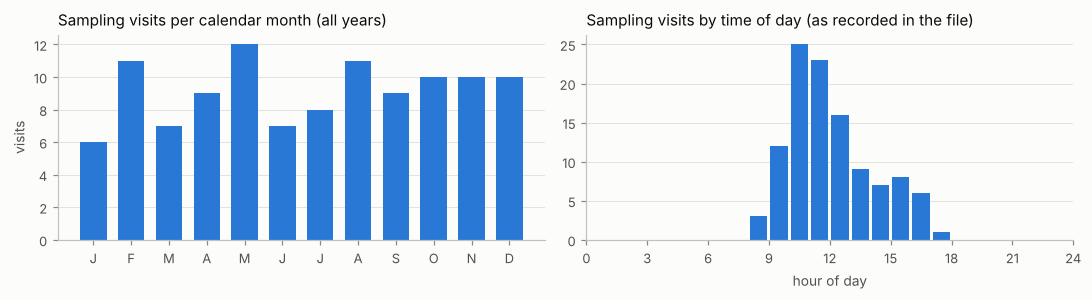

datetime,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
sampling visits,10,3,13,12,12,12,12,12,12,12


Interval between consecutive visits: median 27 d, 90th percentile 54 d, maximum 183 d (ending 2006-04-07).
Time of day: median 11.7 h, range 8.2–17.3 h.


In [7]:
# When were samples taken? (calendar month and time of day — time of day matters for O2 and pH)
visits = pd.Series(wq_wide.index)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
by_month = visits.dt.month.value_counts().reindex(range(1, 13), fill_value=0)
axes[0].bar(by_month.index, by_month.values, width=0.7, color=C_SERIES)
axes[0].set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[0].set_title("Sampling visits per calendar month (all years)")
axes[0].set_ylabel("visits")
hours = visits.dt.hour + visits.dt.minute / 60
axes[1].hist(hours, bins=np.arange(0, 24.5, 1), color=C_SERIES, rwidth=0.85)
axes[1].set_xlim(0, 24)
axes[1].set_xticks(range(0, 25, 3))
axes[1].set_title("Sampling visits by time of day (as recorded in the file)")
axes[1].set_xlabel("hour of day")
for a in axes:
    a.grid(axis="x", visible=False)
fig.tight_layout()
finish(fig, "sampling_calendar")

per_year = visits.dt.year.value_counts().sort_index().rename("visits").to_frame().T
per_year.index = ["sampling visits"]
show_table(per_year, "visits_per_year")
gaps = visits.diff().dt.days.dropna()
print(f"Interval between consecutive visits: median {gaps.median():.0f} d, "
      f"90th percentile {gaps.quantile(0.9):.0f} d, maximum {gaps.max():.0f} d "
      f"(ending {visits[gaps.idxmax()]:%Y-%m-%d}).")
print(f"Time of day: median {hours.median():.1f} h, range {hours.min():.1f}–{hours.max():.1f} h.")

### 3.3 Qualitative results

In [8]:
if len(qual):
    qual_table = (qual.groupby(["det_code", "det_label", "result_raw"])
                  .agg(n=("result_raw", "size"), first=("datetime", "min"), last=("datetime", "max")).reset_index())
    qual_table["first"] = qual_table["first"].dt.date
    qual_table["last"] = qual_table["last"].dt.date
    show_table(qual_table, "qualitative_results", index=False)
else:
    print("No qualitative results in the file.")

,det_code,det_label,result_raw,n,first,last
0,664,"Visible oil or grease, significant trace: Pres...",Not found,106,2004-05-10,2013-12-02
1,3267,Type of flow as description,Normal,44,2004-04-26,2008-06-13
2,6841,Phenolic Odour,Not found,106,2004-05-10,2013-12-02


## 4. Summary statistics

* `n`, `period`: number of results and the period they cover (differs between determinands — see §3.2).
* `% < LOD`: share of results reported below a detection limit.
* Percentiles and the median are rank-based. Where the statistic falls on a censored result it is shown as `<x`.
* `mean`: uses the substitution selected in §1. `mean (bounds)` gives the mean with censored results set to 0 and to
  the detection limit; a wide interval means the mean is not well defined by the data.
* With a high `% < LOD` (roughly above half), only "mostly below the detection limit" and the maximum are robust statements.

In [9]:
def summarise(long_df, meta, keys):
    # Summary statistics per variable, with censored results handled explicitly.
    rows = []
    for k in keys:
        d = long_df[long_df["key"] == k]
        if d.empty:
            continue
        v, c = d["value"].to_numpy(), d["censored"].to_numpy()

        def q(p):
            return q_cens(v, c, p)

        rows.append({
            "group": meta[k]["group"], "variable": meta[k]["label"], "unit": meta[k]["unit"],
            "n": len(v), "period": f"{d['datetime'].min():%Y-%m} to {d['datetime'].max():%Y-%m}",
            "% < LOD": round(100 * c.mean(), 1),
            "min": q(0.0), "p10": q(0.10), "median": q(0.50), "p90": q(0.90), "max": q(1.0),
            "mean": sig(d["value_stat"].mean()),
            "mean (bounds)": (f"{sig(np.where(c, 0, v).mean())}–{sig(v.mean())}" if c.any() else ""),
            "sd": sig(d["value_stat"].std()) if not c.any() else "",
        })
    return pd.DataFrame(rows, index=pd.Index([k for k in keys if (long_df['key'] == k).any()], name="key"))


summary = summarise(wq, META, KEYS)
show_table(summary, "summary_statistics")

,group,variable,unit,n,period,% < LOD,min,p10,median,p90,max,mean,mean (bounds),sd
key,,,,,,,,,,,,,,
temp,Physical,Water temperature,°C,110,2004-04 to 2013-12,0.0,1,5.3,13.7,20.3,27.9,12.9,,6.12
ph,Physical,pH,pH units,110,2004-04 to 2013-12,0.0,7.2,7.9,8.23,8.9,10.4,8.32,,0.482
cond25,Physical,Conductivity at 25 °C,µS/cm,29,2007-11 to 2010-03,0.0,260,277,353,392,399,346,,40.4
cond20,Physical,Conductivity at 20 °C,µS/cm,7,2007-02 to 2007-10,0.0,334,334,362,408,408,369,,28.1
alk,Physical,Alkalinity to pH 4.5,mg/L CaCO3,39,2006-12 to 2010-03,0.0,49,66,93,110,124,88.5,,17.9
ss,Physical,Suspended solids (105 °C),mg/L,110,2004-04 to 2013-12,30.9,<3,<3,4.41,11.4,44.3,5.81,5.35–6.27,
colour,Physical,"Colour, filtered",colour units as reported,34,2007-05 to 2010-03,0.0,5.6,6.7,8.25,12,18,9.14,,2.82
do,Oxygen and organic matter,Dissolved oxygen,mg/L O2,110,2004-04 to 2013-12,0.0,6.29,8.44,10.4,12.6,14,10.5,,1.75
do_sat,Oxygen and organic matter,Dissolved oxygen saturation,%,110,2004-04 to 2013-12,0.0,62.5,80,97.6,113,169,98.8,,15.6


## 5. Time series

One panel per determinand (never two scales on one axis), common time axis so that differences in coverage stay visible.
Filled markers are measured values; **hollow markers are results below the detection limit, drawn at the limit** (the
true value is somewhere below). Lines are broken where consecutive samples are more than 120 days apart.

The plotting functions below take any wide, datetime-indexed table plus a `meta` dictionary, so the same functions are
reused for the meteorological series in §12.

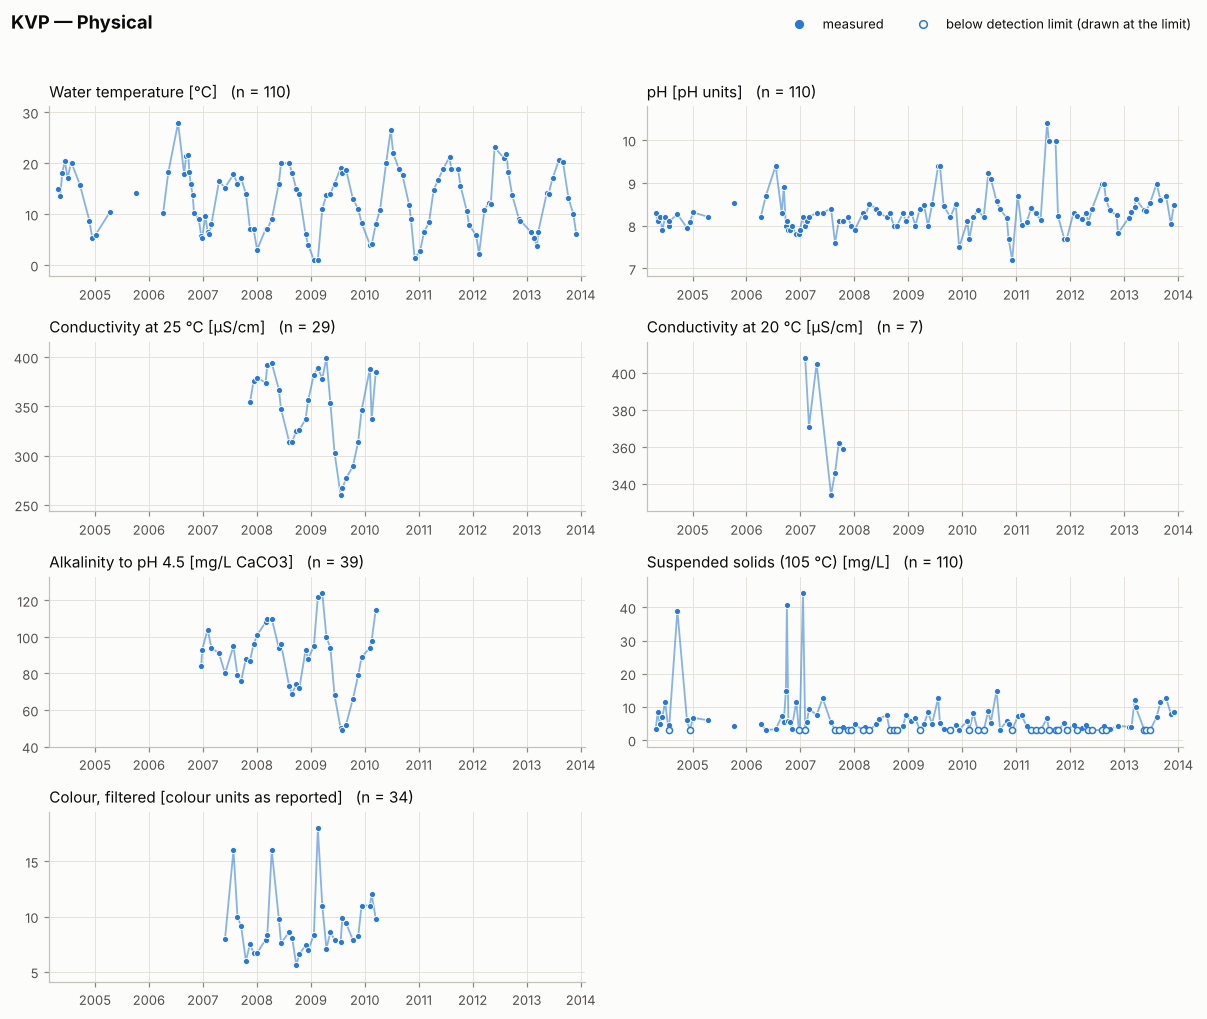

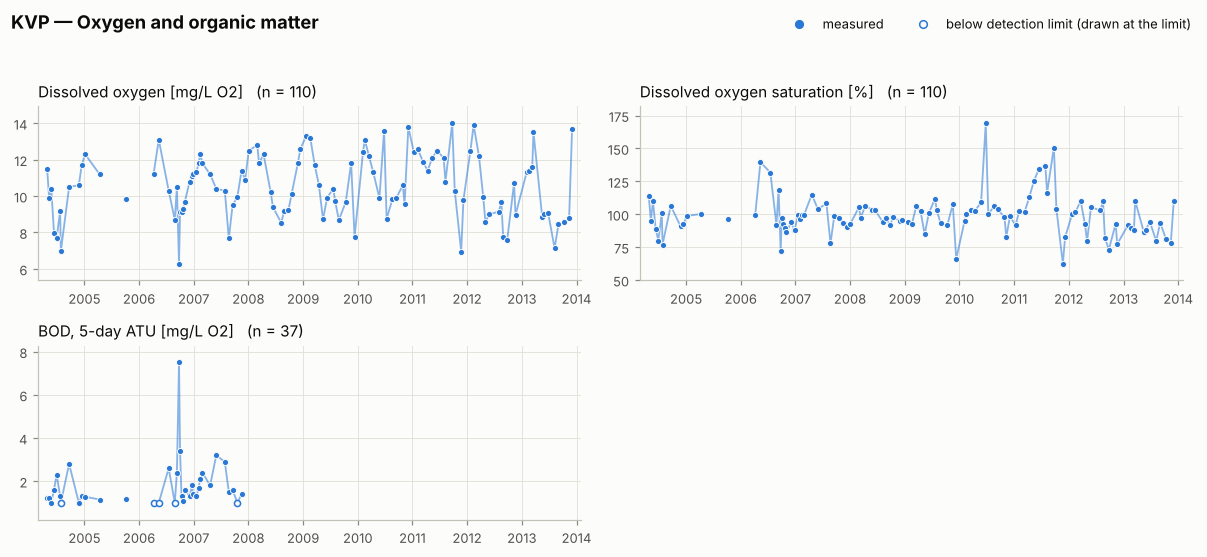

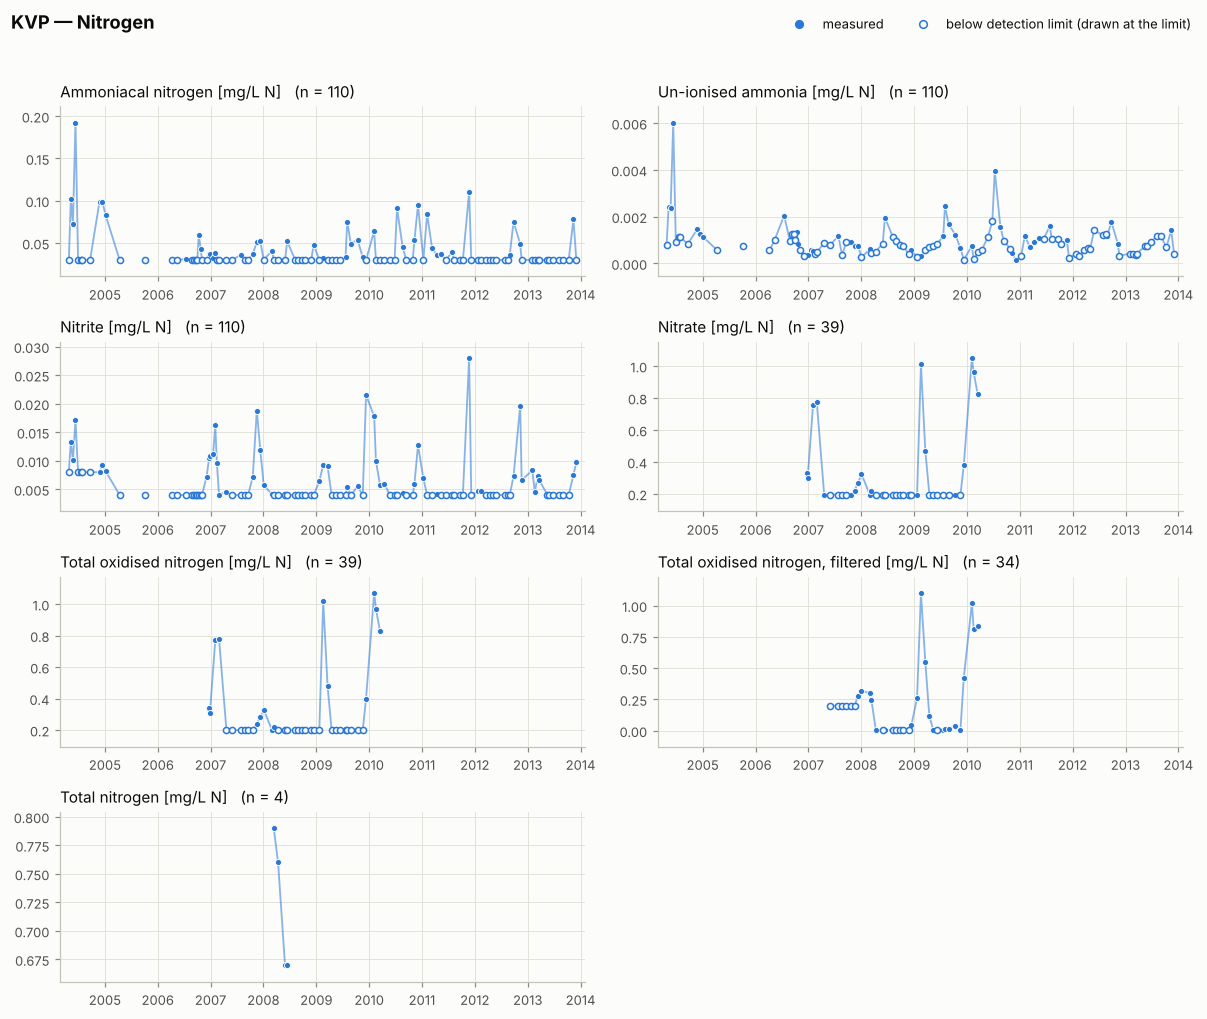

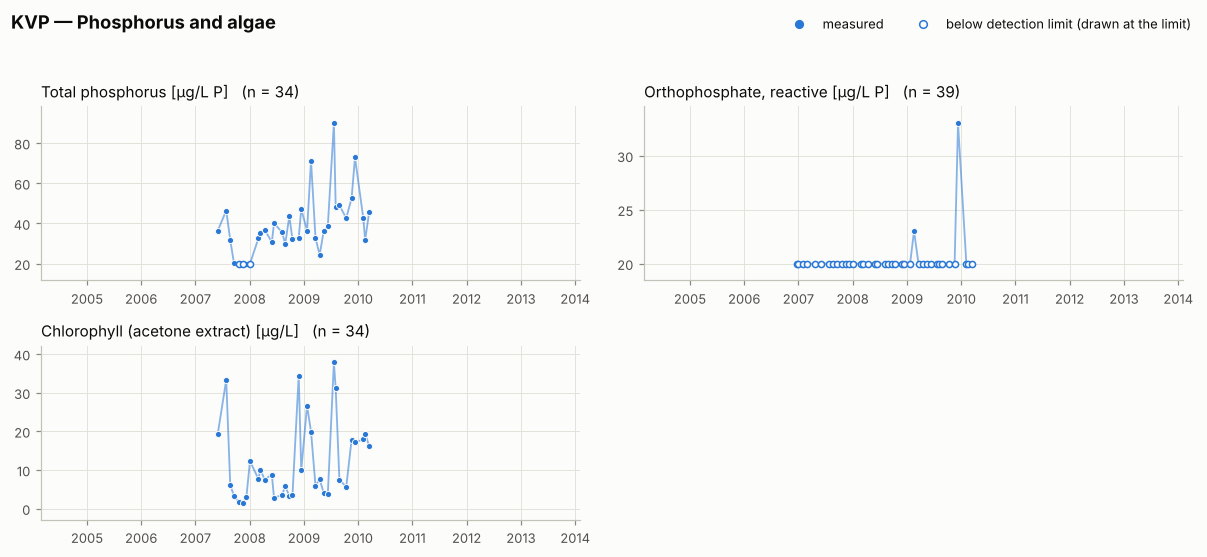

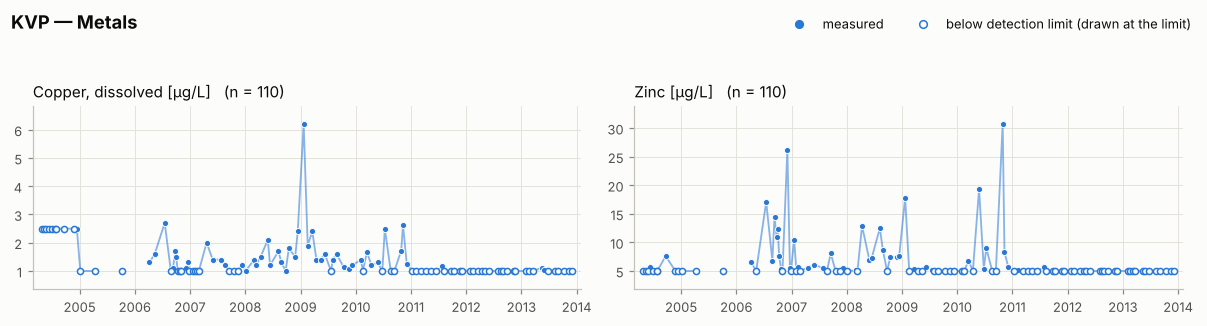

In [10]:
def plot_timeseries_panels(wide, meta, keys, cens=None, title=None, ncols=2, gap_days=120,
                           markers=True, refs=None, xlim=None, panel_height=2.1):
    # Small multiples of time series. `wide`: datetime-indexed table, one column per key.
    keys = [k for k in keys if k in wide and wide[k].notna().any()]
    nrows = int(np.ceil(len(keys) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, panel_height * nrows + 0.9), sharex=True, squeeze=False)
    any_cens = False
    for ax, k in zip(axes.ravel(), keys):
        s = wide[k].dropna()
        line = s.copy() if gap_days is not None else wide[k]      # gap_days=None: missing values break the line
        if gap_days:                                    # break the line across long gaps
            breaks = s.index[1:][np.diff(s.index.values) > np.timedelta64(gap_days, "D")]
            line = pd.concat([line, pd.Series(np.nan, index=breaks - pd.Timedelta(seconds=1))]).sort_index()
        ax.plot(line.index, line.values, color=C_SERIES, lw=1.2 if markers else 0.9, alpha=0.55 if markers else 1, zorder=2)
        if markers:
            c = cens[k].reindex(s.index).fillna(False).to_numpy() if cens is not None and k in cens else np.zeros(len(s), bool)
            ax.plot(s.index[~c], s.values[~c], "o", ms=4, color=C_SERIES, mec=C_SURFACE, mew=0.6, zorder=3)
            if c.any():
                any_cens = True
                ax.plot(s.index[c], s.values[c], "o", ms=4, mfc=C_SURFACE, mec=C_SERIES, mew=1.0, zorder=3)
        for r in (refs or {}).get(k, []):
            ax.axhline(r["y"], color=C_ACCENT, lw=1.0, ls=(0, (4, 2)), zorder=1)
            ax.annotate(r["text"], (1.0, r["y"]), xycoords=("axes fraction", "data"), xytext=(-2, 2),
                        textcoords="offset points", ha="right", va="bottom", fontsize=7.5, color=C_INK2)
        ax.set_title(f"{ax_label(meta, k)}   (n = {len(s)})")
        ax.margins(y=0.12)
    for ax in axes.ravel()[len(keys):]:
        ax.set_visible(False)
    if xlim is None:
        xlim = (wide.index.min() - pd.Timedelta(days=60), wide.index.max() + pd.Timedelta(days=60))
    axes[0, 0].set_xlim(*xlim)
    for ax in axes.ravel()[:len(keys)]:
        ax.tick_params(labelbottom=True)
    handles = None
    if any_cens:
        handles = [Line2D([], [], marker="o", ls="", ms=5, color=C_SERIES, label="measured"),
                   Line2D([], [], marker="o", ls="", ms=5, mfc=C_SURFACE, mec=C_SERIES,
                          label="below detection limit (drawn at the limit)")]
    figure_header(fig, title, handles)
    return fig


def reference_lines(keys):
    # Reference lines to draw (only verified entries unless SHOW_UNVERIFIED_REFERENCE_VALUES is True).
    out = {}
    for r in REFERENCE_VALUES:
        if r["key"] in keys and (r["verified"] or SHOW_UNVERIFIED_REFERENCE_VALUES):
            vals = r["value"] if r["kind"] == "range" else (r["value"],)
            tag = "" if r["verified"] else " [UNVERIFIED]"
            for v in vals:
                out.setdefault(r["key"], []).append(dict(y=v * r["factor"], text=r["label"] + tag))
    return out


for g in GROUP_ORDER:
    keys_g = [k for k in KEYS if META[k]["group"] == g]
    if keys_g:
        fig = plot_timeseries_panels(wq_rep, META, keys_g, cens=wq_cens, refs=reference_lines(keys_g),
                                     title=f"{SITE_SHORT_NAME} — {g}")
        finish(fig, "timeseries_" + g.lower().replace(" ", "_"))

## 6. Seasonality

Each point is one sample placed in its calendar month (all years pooled); the dark bar is the monthly median of the
values as reported. Determinands with a short record have only two to four samples per month, so their seasonal pattern
is indicative only — the points are shown precisely so this is visible.

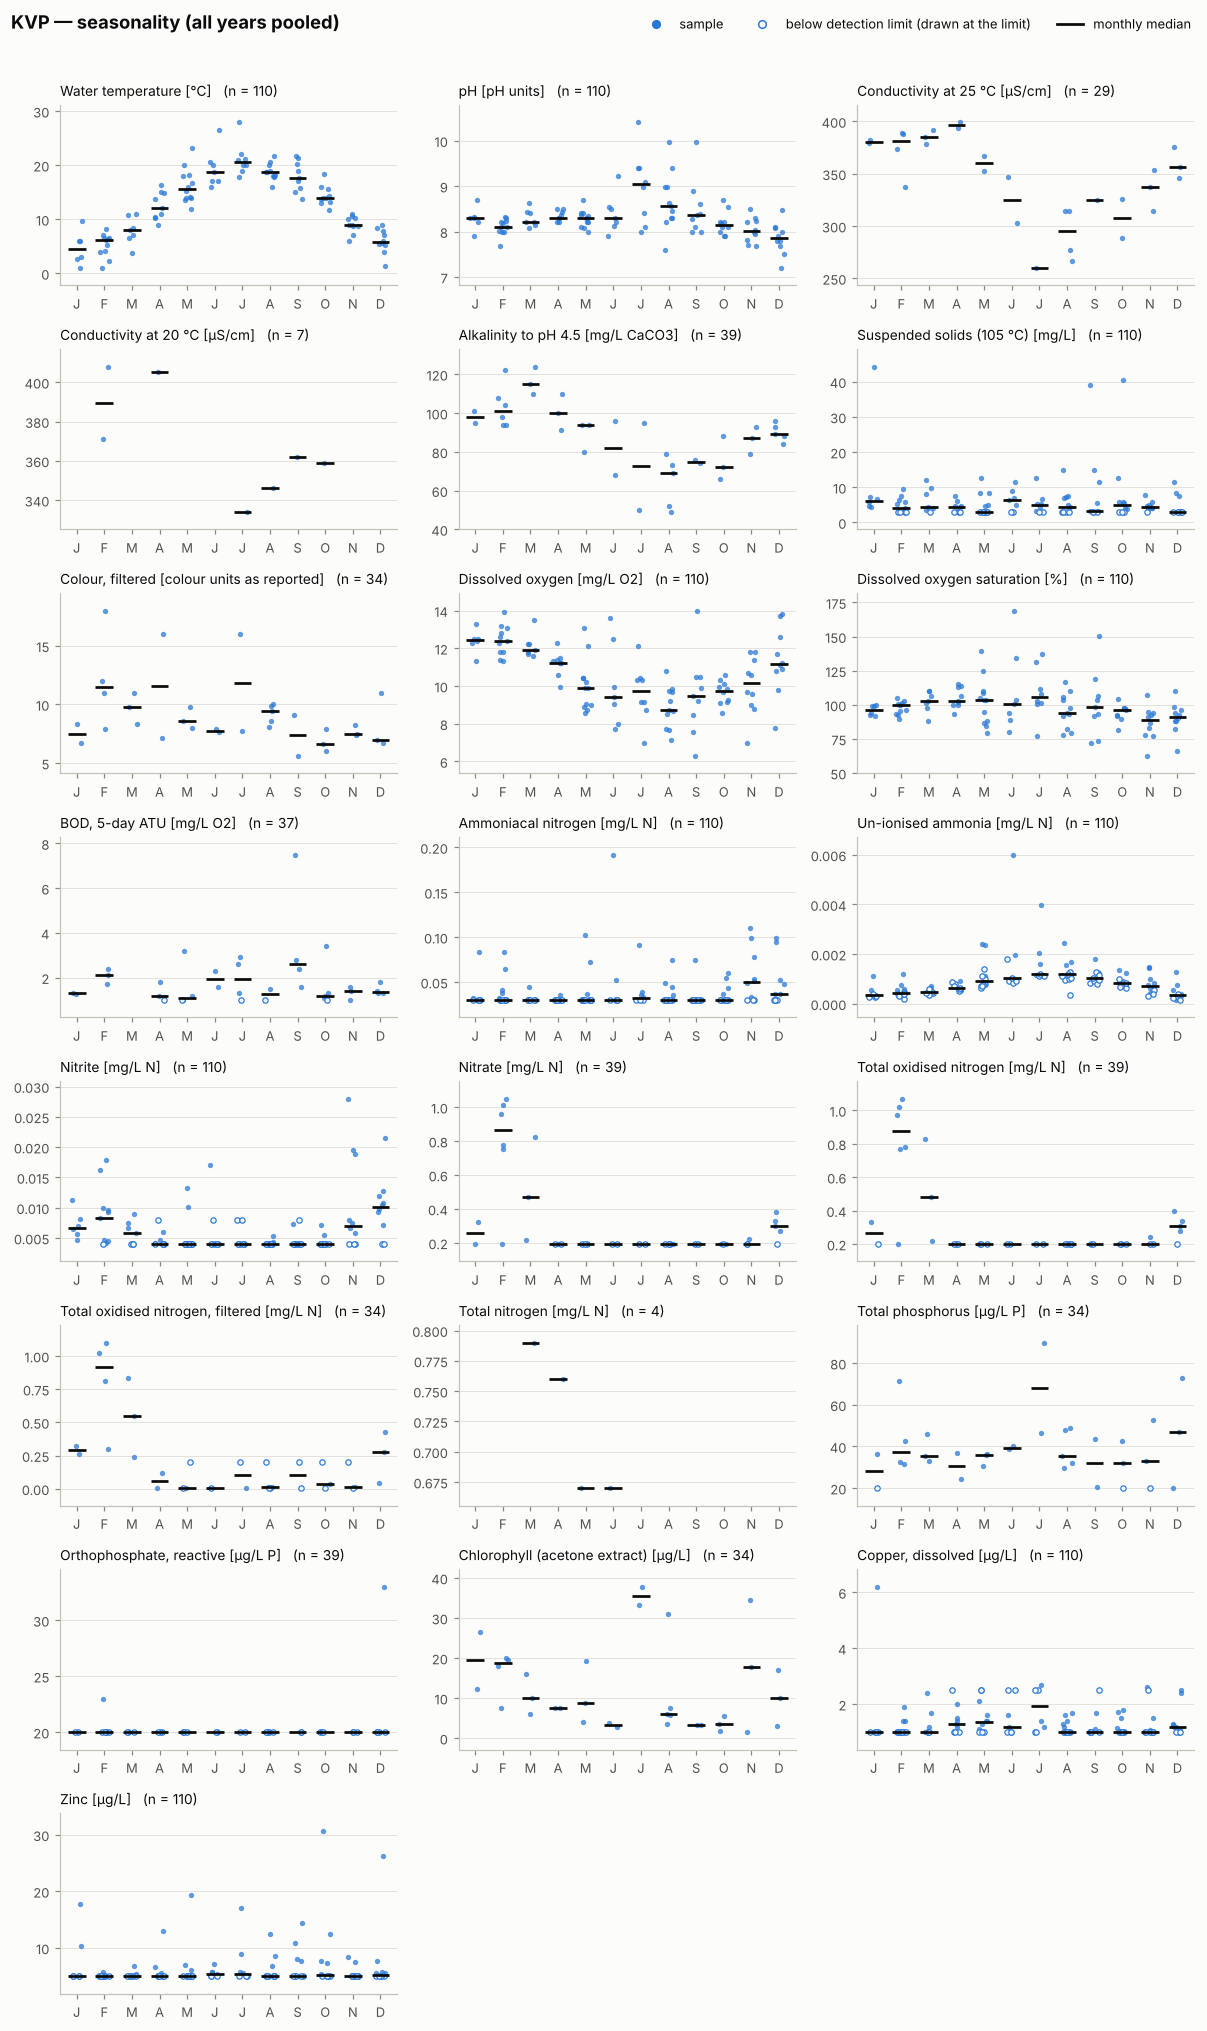

In [11]:
def plot_monthly_panels(wide, meta, keys, cens=None, title=None, ncols=3, panel_height=2.2):
    # Small multiples: values by calendar month (points) with the monthly median (bar).
    keys = [k for k in keys if k in wide and wide[k].notna().any()]
    nrows = int(np.ceil(len(keys) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, panel_height * nrows + 0.9), squeeze=False)
    rng = np.random.default_rng(0)
    any_cens = False
    for ax, k in zip(axes.ravel(), keys):
        s = wide[k].dropna()
        m = s.index.month.to_numpy()
        x = m + rng.uniform(-0.18, 0.18, len(s))
        c = cens[k].reindex(s.index).fillna(False).to_numpy() if cens is not None and k in cens else np.zeros(len(s), bool)
        ax.plot(x[~c], s.values[~c], "o", ms=3.5, color=C_SERIES, alpha=0.75, mec="none", zorder=2)
        if c.any():
            any_cens = True
            ax.plot(x[c], s.values[c], "o", ms=3.5, mfc=C_SURFACE, mec=C_SERIES, mew=0.8, zorder=2)
        med = s.groupby(m).median()
        ax.hlines(med.values, med.index - 0.32, med.index + 0.32, color=C_INK, lw=1.8, zorder=3)
        ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
        ax.set_xlim(0.4, 12.6)
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{ax_label(meta, k)}   (n = {len(s)})", fontsize=9)
        ax.margins(y=0.12)
    for ax in axes.ravel()[len(keys):]:
        ax.set_visible(False)
    handles = [Line2D([], [], marker="o", ls="", ms=5, color=C_SERIES, label="sample"),
               Line2D([], [], color=C_INK, lw=1.8, label="monthly median")]
    if any_cens:
        handles.insert(1, Line2D([], [], marker="o", ls="", ms=5, mfc=C_SURFACE, mec=C_SERIES,
                                 label="below detection limit (drawn at the limit)"))
    figure_header(fig, title, handles)
    return fig


fig = plot_monthly_panels(wq_rep, META, KEYS, cens=wq_cens, title=f"{SITE_SHORT_NAME} — seasonality (all years pooled)")
finish(fig, "seasonality_monthly")

In [12]:
# Seasonal medians ('<x' where the median result is below the detection limit) and number of samples per season
def grouped_median_table(long_df, by, keys, columns=None):
    g = long_df.groupby(["key", by], observed=False)
    med = g.apply(lambda d: q_cens(d["value"], d["censored"], 0.5), include_groups=False).unstack(by).reindex(keys)
    n = g["value"].count().unstack(by).reindex(keys)
    if columns is not None:
        med, n = med.reindex(columns=columns), n.reindex(columns=columns)
    out = pd.concat({"median": med.fillna(""), "n": n.fillna(0).astype(int)}, axis=1)
    out.insert(0, "unit", [META[k]["unit"] for k in out.index])
    out.insert(0, "variable", [META[k]["label"] for k in out.index])
    return out


seasonal = grouped_median_table(wq, "season", KEYS, SEASON_ORDER)
show_table(seasonal, "seasonal_medians")

variable                      unit       median                                                   n                                       
season                                                               Winter (DJF) Spring (MAM) Summer (JJA) Autumn (SON) Winter (DJF) Spring (MAM) Summer (JJA) Autumn (SON)
key                                                                                                                                                                         
temp                     Water temperature                        °C         5.89         13.6         18.9         13.7           27           28           26           29
ph                                      pH                  pH units          8.1          8.3         8.52         8.18           27           28           26           29
cond25               Conductivity at 25 °C                     µS/cm          376          385          303          326            9            7            7            6
cond20               Conductivity at 20 °C                     µS/cm          390          405          340          360            2            1            2            2
alk                   Alkalinity to pH 4.5                mg/L CaCO3           95          100           69         77.5           13            9            9            8
ss               Suspended solids (105 °C)                      mg/L         4.42         4.15         4.95          4.3           27           28           26           29
colour                    Colour, filtered  colour units as reported          8.3          9.2          8.6         7.45            9            8            9            8
do                        Dissolved oxygen                   mg/L O2         12.3         11.2         9.18         9.69           27           28           26           29
do_sat         Dissolved oxygen saturation                         %         95.1          103          101         93.6           27           28           26           29
bod                         BOD, 5-day ATU                   mg/L O2          1.4         1.17         1.55          1.5            9            8            8           12
nh4_n                  Ammoniacal nitrogen                    mg/L N        <0.03        <0.03        <0.03        <0.03           27           28           26           29
nh3_n                   Un-ionised ammonia                    mg/L N      <0.0004     <0.00073     <0.00118     <0.00084           27           28           26           29
no2_n                              Nitrite                    mg/L N       0.0083       <0.004       <0.004       <0.004           27           28           26           29
no3_n                              Nitrate                    mg/L N         0.33       <0.196       <0.196       <0.196           13            9            9            8
ton_n              Total oxidised nitrogen                    mg/L N         0.34         <0.2         <0.2         <0.2           13            9            9            8
ton_f_n  Total oxidised nitrogen, filtered                    mg/L N         0.32         <0.2       0.0065       0.0226            9            8            9            8
tn                          Total nitrogen                    mg/L N                      0.76         0.67                         0            3            1            0
tp                        Total phosphorus                    µg/L P         36.3         35.6         40.1         32.5            9            8            9            8
srp               Orthophosphate, reactive                    µg/L P          <20          <20          <20          <20           13            9            9            8
chla         Chlorophyll (acetone extract)                      µg/L         17.1          8.2          6.1          3.4            9            8            9            8
cu_diss                  Copper, dissolved             

## 7. Inter-annual variability and trends

Restricted to determinands with a long record (setting `LONG_RECORD_MIN_YEARS`). Boxes show the inter-quartile range and
median per calendar year, whiskers reach to the most extreme sample within 1.5 × IQR, and all individual samples are
overlaid. **Years differ in the number and timing of samples** (see §3.2 — one early year has very few), so a box for
such a year is not comparable with the others.

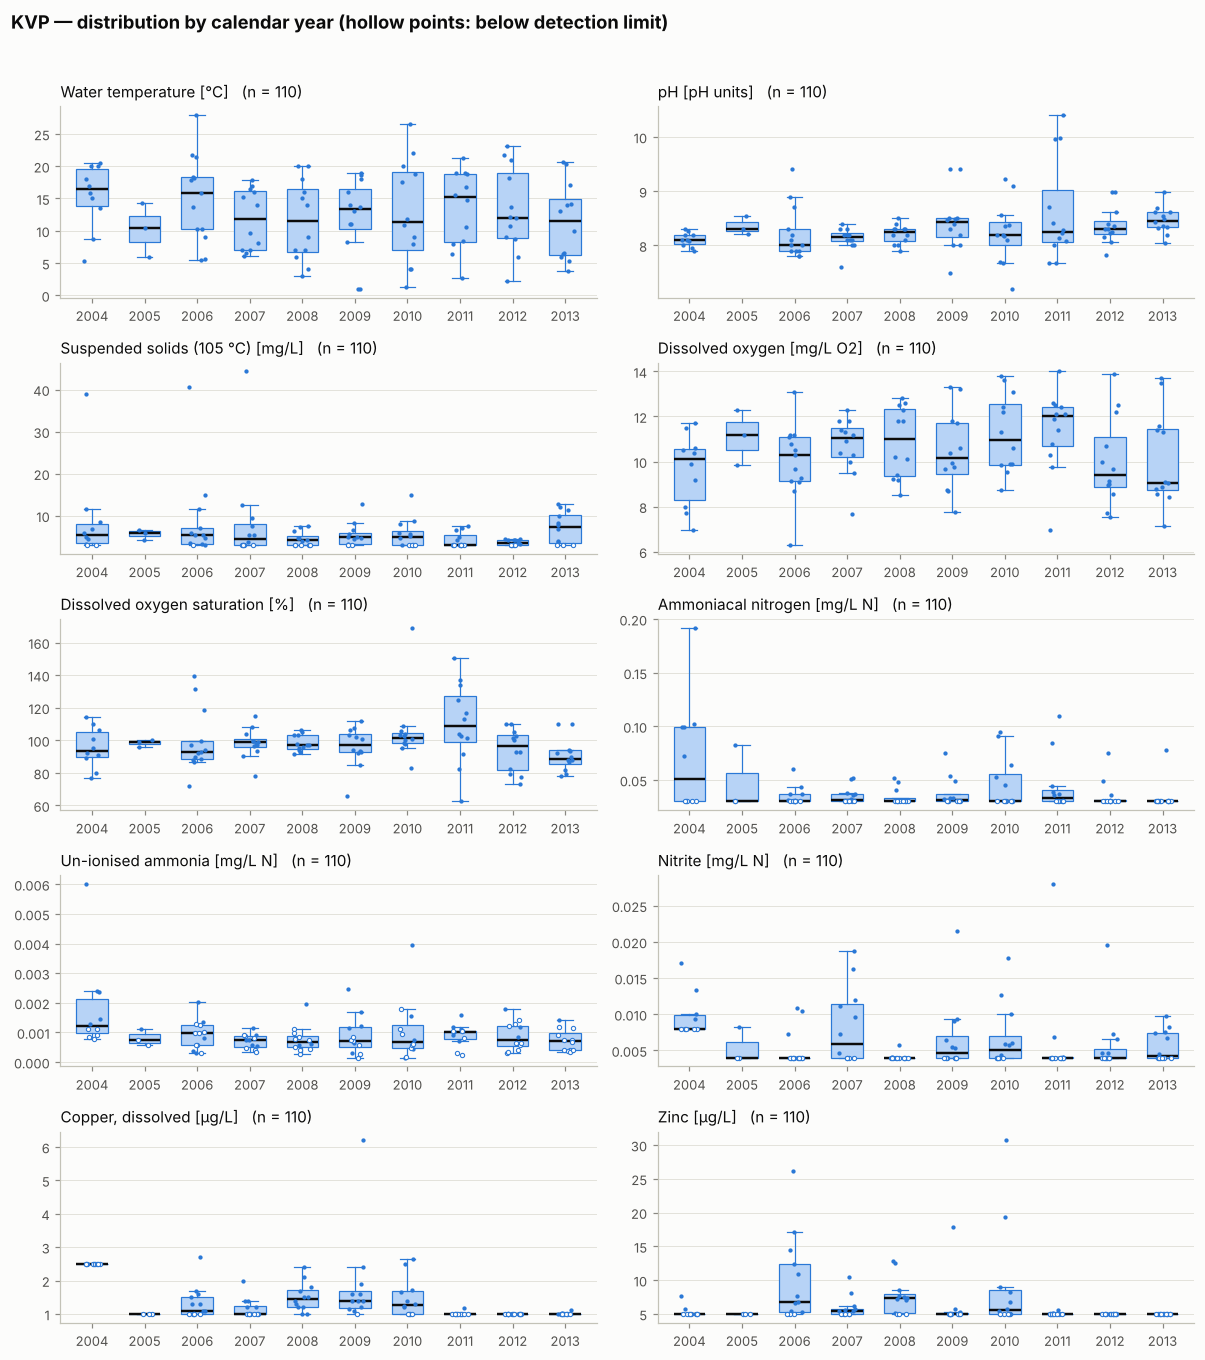

Annual medians ('<x': the median result is below the detection limit) and number of samples:


variable      unit    median                                                                                              n                                             
year                                                2004      2005      2006      2007      2008      2009      2010      2011      2012      2013 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
key                                                                                                                                                                                                 
temp               Water temperature        °C      16.4      10.4      15.9      11.8      11.5      13.4      11.3      15.2        12      11.6   10    3   13   12   12   12   12   12   12   12
ph                                pH  pH units       8.1      8.31         8      8.15      8.25      8.43       8.2      8.25       8.3      8.46   10    3   13   12   12   12   12   12   12   12
ss         Suspended solids (105 °C)      mg/L       5.4         6       5.5      4.55      4.15      4.85      4.99        <3      3.51      7.36   10    3   13   12   12   12   12   12   12   12
do                  Dissolved oxygen   mg/L O2      10.1      11.2      10.3      11.1        11      10.2      10.9        12      9.41      9.05   10    3   13   12   12   12   12   12   12   12
do_sat   Dissolved oxygen saturation         %      93.7      98.8      92.7      98.8      97.3      97.3       102       109      96.5      88.8   10    3   13   12   12   12   12   12   12   12
nh4_n            Ammoniacal nitrogen    mg/L N    <0.072     <0.03     <0.03    <0.032     <0.03    <0.032     <0.03    <0.036     <0.03     <0.03   10    3   13   12   12   12   12   12   12   12
nh3_n             Un-ionised ammonia    mg/L N  <0.00128  <0.00075  <0.00097  0.000755  <0.00073  <0.00073  <0.00075  <0.00104  <0.00083  <0.00073   10    3   13   12   12   12   12   12   12   12
no2_n                        Nitrite    mg/L N    <0.008    <0.004    <0.004    0.0059    <0.004   <0.0054    0.0051    <0.004    <0.004   <0.0045   10    3   13   12   12   12   12   12   12   12
cu_diss            Copper, dissolved      µg/L      <2.5        <1       1.1        <1      1.45       1.4      1.27        <1        <1        <1   10    3   13   12   12   12   12   12   12   12
zn                              Zinc      µg/L        <5        <5       6.8       5.5       7.3        <5      5.55        <5        <5        <5   10    3   13   12   12   12   12   12   12   12

In [13]:
n_years = wq.groupby("key")["year"].nunique()
LONG_KEYS = [k for k in KEYS if n_years.get(k, 0) >= LONG_RECORD_MIN_YEARS]


def plot_annual_boxes(wide, meta, keys, cens=None, title=None, ncols=2, panel_height=2.3):
    keys = [k for k in keys if k in wide and wide[k].notna().any()]
    nrows = int(np.ceil(len(keys) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, panel_height * nrows + 0.9), squeeze=False)
    rng = np.random.default_rng(1)
    years_all = range(wide.index.year.min(), wide.index.year.max() + 1)
    for ax, k in zip(axes.ravel(), keys):
        s = wide[k].dropna()
        yrs = sorted(s.index.year.unique())
        ax.boxplot([s[s.index.year == y].values for y in yrs], positions=yrs, widths=0.6, showfliers=False,
                   patch_artist=True, boxprops=dict(facecolor=C_SERIES_LIGHT, edgecolor=C_SERIES, lw=0.8),
                   medianprops=dict(color=C_INK, lw=1.6), whiskerprops=dict(color=C_SERIES, lw=0.8),
                   capprops=dict(color=C_SERIES, lw=0.8), zorder=2)
        c = cens[k].reindex(s.index).fillna(False).to_numpy() if cens is not None and k in cens else np.zeros(len(s), bool)
        x = s.index.year.to_numpy() + rng.uniform(-0.16, 0.16, len(s))
        ax.plot(x[~c], s.values[~c], "o", ms=2.8, color=C_SERIES, mec="none", zorder=3)
        if c.any():
            ax.plot(x[c], s.values[c], "o", ms=2.8, mfc=C_SURFACE, mec=C_SERIES, mew=0.7, zorder=3)
        ax.set_xticks(list(years_all), [str(y) for y in years_all])
        ax.set_xlim(min(years_all) - 0.6, max(years_all) + 0.6)
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{ax_label(meta, k)}   (n = {len(s)})")
    for ax in axes.ravel()[len(keys):]:
        ax.set_visible(False)
    figure_header(fig, title)
    return fig


fig = plot_annual_boxes(wq_rep, META, LONG_KEYS, cens=wq_cens,
                        title=f"{SITE_SHORT_NAME} — distribution by calendar year (hollow points: below detection limit)")
finish(fig, "interannual_boxes")

annual_median = grouped_median_table(wq[wq["key"].isin(LONG_KEYS)], "year", LONG_KEYS)
print("Annual medians ('<x': the median result is below the detection limit) and number of samples:")
show_table(annual_median, "annual_medians")

### Monotonic trend — seasonal Mann–Kendall test and seasonal Kendall (Sen) slope

Non-parametric test for a monotonic trend that compares each calendar month only with the same month in other years,
so the seasonal cycle does not mask or mimic a trend. Implementation notes and limits:

* one value per month and year (median if several); tie correction included in the variance;
* censored results: all results at or below the **highest** detection limit of that determinand are set equal to that
  limit before ranking (they become ties), so changes in detection limit cannot create a spurious trend. The slope is then
  biased towards zero for partly censored determinands;
* **serial correlation is not accounted for** (it would make p-values too small), and no correction for multiple testing
  is applied. Treat p-values as screening information, not as proof;
* sampling was at varying times of day (§3.2); for O2 and pH a drift in sampling time could appear as a trend. This is not tested here.

In [14]:
def seasonal_mann_kendall(s, censored=None):
    # Seasonal (monthly) Mann–Kendall test and seasonal Kendall slope for a datetime-indexed series.
    s = s.dropna()
    if censored is not None and censored.reindex(s.index).fillna(False).any():
        lod_max = s[censored.reindex(s.index).fillna(False)].max()
        s = s.clip(lower=lod_max)                        # recensor everything to the highest limit
    df = pd.DataFrame({"v": s.values, "y": s.index.year, "m": s.index.month})
    df = df.groupby(["m", "y"], as_index=False)["v"].median()
    S, var, slopes = 0.0, 0.0, []
    for _, d in df.groupby("m"):
        v, y = d["v"].to_numpy(), d["y"].to_numpy()
        n = len(v)
        if n < 2:
            continue
        i, j = np.triu_indices(n, k=1)
        S += np.sign(v[j] - v[i]).sum()
        ties = np.unique(v, return_counts=True)[1]
        var += (n * (n - 1) * (2 * n + 5) - (ties * (ties - 1) * (2 * ties + 5)).sum()) / 18.0
        slopes.extend((v[j] - v[i]) / (y[j] - y[i]))
    if var <= 0:
        return dict(S=S, z=np.nan, p=np.nan, slope=np.nan, n=len(df))
    z = (S - np.sign(S)) / np.sqrt(var)
    return dict(S=S, z=z, p=2 * stats.norm.sf(abs(z)), slope=float(np.median(slopes)), n=len(df))


rows = []
for k in LONG_KEYS:
    frac_c = wq_cens[k][wq_rep[k].notna()].mean()
    if frac_c > TREND_MAX_CENSORED:
        rows.append(dict(key=k, variable=META[k]["label"], unit=META[k]["unit"], **{"% < LOD": round(100 * frac_c, 1)},
                         note=f"not tested (more than {100 * TREND_MAX_CENSORED:.0f} % censored)"))
        continue
    r = seasonal_mann_kendall(wq_rep[k], wq_cens[k])
    med = wq_wide[k].median()
    rows.append(dict(key=k, variable=META[k]["label"], unit=META[k]["unit"], **{"% < LOD": round(100 * frac_c, 1)},
                     n_months=r["n"], S=r["S"], z=round(r["z"], 2), p=round(r["p"], 4),
                     **{"slope [unit/yr]": float(sig(r["slope"])) if np.isfinite(r["slope"]) else np.nan,
                        "slope [% of median/yr]": round(100 * r["slope"] / med, 2) if med else np.nan},
                     note=("increasing" if r["z"] > 0 else "decreasing") + f" (p < {TREND_ALPHA})" if r["p"] < TREND_ALPHA
                     else f"no trend detected at p < {TREND_ALPHA}"))
trends = pd.DataFrame(rows).set_index("key")
print(f"Period tested: {wq_rep.index.min():%Y-%m} to {wq_rep.index.max():%Y-%m}")
show_table(trends, "trends_seasonal_mann_kendall")

Period tested: 2004-04 to 2013-12


,variable,unit,% < LOD,n_months,S,z,p,slope [unit/yr],slope [% of median/yr],note
key,,,,,,,,,,
temp,Water temperature,°C,0.0,91.0,10.0,0.34,0.7355,0.0517,0.38,no trend detected at p < 0.05
ph,pH,pH units,0.0,91.0,63.0,2.34,0.0195,0.0260,0.32,increasing (p < 0.05)
ss,Suspended solids (105 °C),mg/L,30.9,91.0,-21.0,-0.77,0.4430,0.0000,0.00,no trend detected at p < 0.05
do,Dissolved oxygen,mg/L O2,0.0,91.0,0.0,0.00,1.0000,0.0000,0.00,no trend detected at p < 0.05
do_sat,Dissolved oxygen saturation,%,0.0,91.0,-13.0,-0.45,0.6527,-0.4500,-0.46,no trend detected at p < 0.05
nh4_n,Ammoniacal nitrogen,mg/L N,62.7,NaN,NaN,NaN,NaN,NaN,NaN,not tested (more than 50 % censored)
nh3_n,Un-ionised ammonia,mg/L N,62.7,NaN,NaN,NaN,NaN,NaN,NaN,not tested (more than 50 % censored)
no2_n,Nitrite,mg/L N,58.2,NaN,NaN,NaN,NaN,NaN,NaN,not tested (more than 50 % censored)
cu_diss,"Copper, dissolved",µg/L,55.5,NaN,NaN,NaN,NaN,NaN,NaN,not tested (more than 50 % censored)


## 8. Oxygen regime

Oxygen saturation relates the measured concentration to the solubility at the water temperature, so it separates
biological/physical effects from the temperature effect on solubility. Values above 100 % indicate net production
(photosynthesis) or recent warming; values well below 100 % indicate net consumption. All samples here are daytime
spot samples at one point (§3.2), so they cannot show night-time minima or conditions at depth.

The bins in the table are **descriptive only** (editable in §1), not regulatory classes.

,Winter (DJF),Spring (MAM),Summer (JJA),Autumn (SON),all samples,% of samples
O2 saturation,,,,,,
0 to <60 %,0,0,0,0,0,0.0
60 to <80 %,1,1,3,5,10,9.1
80 to <100 %,20,8,8,18,54,49.1
100 to <120 %,6,17,11,5,39,35.5
≥ 120 %,0,2,4,1,7,6.4


O2 saturation: minimum 62.5 % on 2011-11-22, maximum 169.1 % on 2010-06-25; O2 concentration minimum 6.29 mg/L on 2006-09-24.


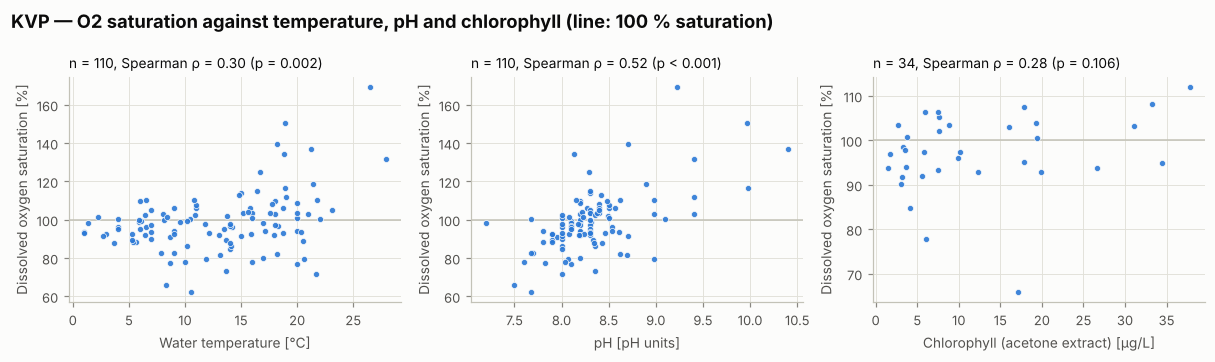

In [15]:
if "do_sat" in wq_wide:
    dos = wq_wide["do_sat"].dropna()
    binned = pd.cut(dos, DO_SAT_BINS, right=False)
    do_bins = pd.crosstab(binned, pd.Categorical(dos.index.month.map(SEASONS), SEASON_ORDER, ordered=True), dropna=False)
    do_bins.columns = [str(c) for c in do_bins.columns]
    do_bins["all samples"] = do_bins.sum(axis=1)
    do_bins["% of samples"] = (100 * do_bins["all samples"] / len(dos)).round(1)
    do_bins.index = [f"{iv.left:g} to <{iv.right:g} %" if np.isfinite(iv.right) else f"≥ {iv.left:g} %" for iv in do_bins.index]
    do_bins.index.name = "O2 saturation"
    show_table(do_bins, "do_saturation_bins")
    print(f"O2 saturation: minimum {dos.min():g} % on {dos.idxmin():%Y-%m-%d}, maximum {dos.max():g} % on {dos.idxmax():%Y-%m-%d}; "
          f"O2 concentration minimum {wq_wide['do'].min():g} mg/L on {wq_wide['do'].idxmin():%Y-%m-%d}.")

    pairs = [(x, "do_sat") for x in ("temp", "ph", "chla") if x in wq_wide]
    fig, axes = plt.subplots(1, len(pairs), figsize=(3.7 * len(pairs), 3.3), squeeze=False)
    for ax, (xk, yk) in zip(axes.ravel(), pairs):
        d = wq_wide[[xk, yk]].dropna()
        ax.axhline(100, color=C_AXIS, lw=1.0, zorder=1)
        ax.plot(d[xk], d[yk], "o", ms=4, color=C_SERIES, mec=C_SURFACE, mew=0.5, alpha=0.9, zorder=2)
        rho, p = stats.spearmanr(d[xk], d[yk])
        ax.set_xlabel(ax_label(META, xk))
        ax.set_ylabel(ax_label(META, yk))
        ax.set_title(f"n = {len(d)}, Spearman ρ = {rho:.2f} ({'p < 0.001' if p < 0.001 else f'p = {p:.3f}'})", fontsize=9)
    fig.suptitle(f"{SITE_SHORT_NAME} — O2 saturation against temperature, pH and chlorophyll (line: 100 % saturation)",
                 x=0.01, ha="left")
    fig.tight_layout()
    finish(fig, "oxygen_relationships")

## 9. Nutrients, chlorophyll-a and trophic state

Total phosphorus (TP) and chlorophyll are available for part of the record only (see §3.2), so the trophic assessment
describes **that period**, not 2004–2013 as a whole. No transparency (Secchi depth) data are in the file.

Two schemes are computed:

* **OECD fixed-boundary classification** — OECD (1982), *Eutrophication of Waters: Monitoring, Assessment and Control*
  (Vollenweider & Kerekes) — based on annual mean TP, annual mean chlorophyll-a and annual maximum chlorophyll-a.
  The class limits are in `TROPHIC_BOUNDARIES` (§1) and were **entered from memory; please check them against the report**.
* **Carlson trophic state index** — Carlson (1977), *A trophic state index for lakes*, Limnology and Oceanography 22(2), 361–369:
  `TSI(TP) = 14.42 ln(TP) + 4.15` and `TSI(Chl) = 9.81 ln(Chl) + 30.6`, TP and Chl in µg/L. These equations are also quoted
  from memory — **please check them against the paper**. I give no class limits for the TSI because I do not have a
  verified source for them.

Caveats: (i) the chlorophyll determinand is "Chlorophyll : Acetone Extract" — the file does not say whether this is
chlorophyll-a specifically or whether it is corrected for phaeopigments; (ii) calendar years with incomplete coverage
(see column `n` and `months sampled`) do not give a true annual mean or maximum, because algal biomass is seasonal;
(iii) both schemes were derived from sets of lakes that may differ from this site.

NOTE: OECD class limits and TSI equations are UNVERIFIED (entered from memory) — see text above and §1.


,n TP,n Chl,months sampled,TP mean [µg/L],Chl mean [µg/L],Chl max [µg/L],OECD class (TP mean),OECD class (Chl mean),OECD class (Chl max),TSI(TP),TSI(Chl)
2007,7,7,7,25.0,9.8,33.3,mesotrophic,eutrophic,eutrophic,50.6,52.9
2008,12,12,11,33.9,9.1,34.4,mesotrophic,eutrophic,eutrophic,54.9,52.3
2009,12,12,11,49.5,15.4,37.8,eutrophic,eutrophic,eutrophic,60.4,57.4
2010,3,3,2,40.0,17.8,19.4,eutrophic,eutrophic,mesotrophic,57.4,58.8
all samples (2007-05 to 2010-03),34,34,12,38.1,12.2,37.8,eutrophic,eutrophic,eutrophic,56.6,55.2


TP results below detection limit: 3 of 34 (substitution 'half' used in the means).


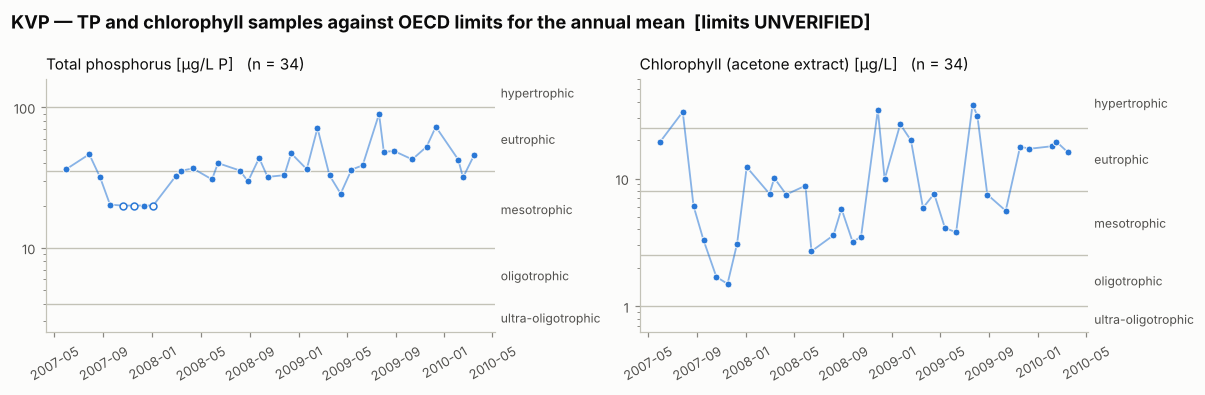

In [16]:
def trophic_class(value, bounds):
    if not np.isfinite(value):
        return ""
    return TROPHIC_CLASSES[int(np.searchsorted(bounds, value, side="right"))]


def trophic_row(d):
    tp, ch = d["tp"].dropna() if "tp" in d else pd.Series(dtype=float), d["chla"].dropna() if "chla" in d else pd.Series(dtype=float)
    r = {"n TP": len(tp), "n Chl": len(ch), "months sampled": d.dropna(how="all").index.month.nunique(),
         "TP mean [µg/L]": tp.mean(), "Chl mean [µg/L]": ch.mean(), "Chl max [µg/L]": ch.max()}
    r["OECD class (TP mean)"] = trophic_class(r["TP mean [µg/L]"], TROPHIC_BOUNDARIES["tp_mean"])
    r["OECD class (Chl mean)"] = trophic_class(r["Chl mean [µg/L]"], TROPHIC_BOUNDARIES["chla_mean"])
    r["OECD class (Chl max)"] = trophic_class(r["Chl max [µg/L]"], TROPHIC_BOUNDARIES["chla_max"])
    r["TSI(TP)"] = 14.42 * np.log(r["TP mean [µg/L]"]) + 4.15 if len(tp) else np.nan
    r["TSI(Chl)"] = 9.81 * np.log(r["Chl mean [µg/L]"]) + 30.6 if len(ch) else np.nan
    return r


tro_keys = [k for k in ("tp", "chla") if k in wq_wide]
if tro_keys:
    tw = wq_wide[tro_keys].dropna(how="all")
    rows = {str(y): trophic_row(d) for y, d in tw.groupby(tw.index.year)}
    rows[f"all samples ({tw.index.min():%Y-%m} to {tw.index.max():%Y-%m})"] = trophic_row(tw)
    trophic = pd.DataFrame(rows).T
    num = ["TP mean [µg/L]", "Chl mean [µg/L]", "Chl max [µg/L]", "TSI(TP)", "TSI(Chl)"]
    trophic[num] = trophic[num].astype(float).round(1)
    if not TROPHIC_BOUNDARIES_VERIFIED:
        print("NOTE: OECD class limits and TSI equations are UNVERIFIED (entered from memory) — see text above and §1.")
    show_table(trophic, "trophic_state")
    if "tp" in wq_cens:
        print(f"TP results below detection limit: {int(wq_cens['tp'][wq_rep['tp'].notna()].sum())} of {wq_rep['tp'].notna().sum()} "
              f"(substitution '{CENSORED_SUBSTITUTION}' used in the means).")

    # TP and chlorophyll with the class limits (log axis; one panel per variable)
    fig, axes = plt.subplots(1, len(tro_keys), figsize=(5.5 * len(tro_keys), 3.6), squeeze=False)
    for ax, k in zip(axes.ravel(), tro_keys):
        s = wq_rep[k].dropna()
        c = wq_cens[k].reindex(s.index).to_numpy()
        ax.plot(s.index, s.values, color=C_SERIES, lw=1.2, alpha=0.55, zorder=2)
        ax.plot(s.index[~c], s.values[~c], "o", ms=4.5, color=C_SERIES, mec=C_SURFACE, mew=0.6, zorder=3)
        ax.plot(s.index[c], s.values[c], "o", ms=4.5, mfc=C_SURFACE, mec=C_SERIES, mew=1.0, zorder=3)
        ax.set_yscale("log")
        bounds = TROPHIC_BOUNDARIES["tp_mean" if k == "tp" else "chla_mean"]
        lo, hi = min(s.min(), bounds[0]) / 1.6, max(s.max(), bounds[-1]) * 1.6
        ax.set_ylim(lo, hi)
        edges = [lo] + list(bounds) + [hi]
        for b in bounds:
            ax.axhline(b, color=C_AXIS, lw=0.9, zorder=1)
        for name, a, b in zip(TROPHIC_CLASSES, edges[:-1], edges[1:]):
            ax.annotate(name, (1.0, np.sqrt(a * b)), xycoords=("axes fraction", "data"), xytext=(4, 0),
                        textcoords="offset points", ha="left", va="center", fontsize=8, color=C_INK2)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.grid(False)
        ax.tick_params(axis="x", labelrotation=30)
        ax.set_title(f"{ax_label(META, k)}   (n = {len(s)})")
    fig.suptitle(f"{SITE_SHORT_NAME} — TP and chlorophyll samples against OECD limits for the annual mean"
                 + ("" if TROPHIC_BOUNDARIES_VERIFIED else "  [limits UNVERIFIED]"), x=0.01, ha="left")
    fig.tight_layout()
    finish(fig, "trophic_state")
else:
    print("No total phosphorus or chlorophyll data in the file.")

### Nitrogen and phosphorus forms

The table restates, for the nutrient determinands, how many results are quantified. Where nearly all results of a
dissolved inorganic form are below the detection limit (check `% < LOD`), ratios such as dissolved inorganic N : soluble
reactive P cannot be computed meaningfully, so none is computed here. Total N has too few results in this file for a TN : TP assessment
(see `n`).

In [17]:
nut_keys = [k for k in KEYS if META[k]["group"] in ("Nitrogen", "Phosphorus and algae")]
show_table(summary.loc[nut_keys, ["variable", "unit", "n", "period", "% < LOD", "median", "p90", "max"]], "nutrient_forms")

,variable,unit,n,period,% < LOD,median,p90,max
key,,,,,,,,
nh4_n,Ammoniacal nitrogen,mg/L N,110,2004-04 to 2013-12,62.7,<0.03,0.075,0.192
nh3_n,Un-ionised ammonia,mg/L N,110,2004-04 to 2013-12,62.7,<0.00082,0.00155,0.00601
no2_n,Nitrite,mg/L N,110,2004-04 to 2013-12,58.2,<0.004,0.0108,0.028
no3_n,Nitrate,mg/L N,39,2006-12 to 2010-03,48.7,<0.196,0.824,1.05
ton_n,Total oxidised nitrogen,mg/L N,39,2006-12 to 2010-03,61.5,<0.2,0.83,1.07
ton_f_n,"Total oxidised nitrogen, filtered",mg/L N,34,2007-05 to 2010-03,38.2,<0.2,0.811,1.1
tn,Total nitrogen,mg/L N,4,2008-03 to 2008-06,0.0,0.715,0.79,0.79
tp,Total phosphorus,µg/L P,34,2007-05 to 2010-03,8.8,36.1,52.5,89.8
srp,"Orthophosphate, reactive",µg/L P,39,2006-12 to 2010-03,94.9,<20,<20,33


## 10. Relationships between variables

Spearman rank correlation between determinands measured in the same sample (rank-based, so robust to skew and to the
substitution used for censored results as long as a determinand has a single detection limit). Shown only for pairs
with at least `CORR_MIN_N` common samples and determinands with at most `CORR_MAX_CENSORED` censored results.
Correlation between two seasonal variables largely reflects their shared seasonal cycle and is **not** evidence of a causal link.

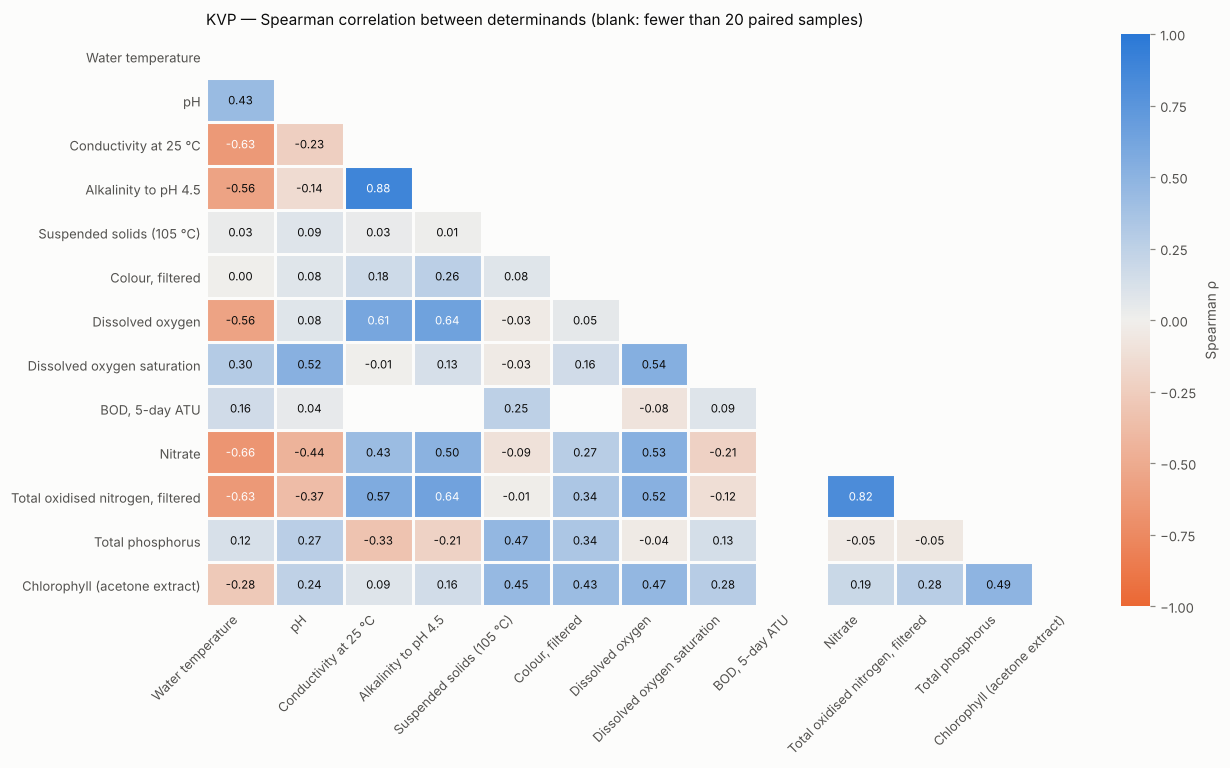

Number of paired samples behind each coefficient:


key,Water temperature,pH,Conductivity at 25 °C,Alkalinity to pH 4.5,Suspended solids (105 °C),"Colour, filtered",Dissolved oxygen,Dissolved oxygen saturation,"BOD, 5-day ATU",Nitrate,"Total oxidised nitrogen, filtered",Total phosphorus,Chlorophyll (acetone extract)
key,,,,,,,,,,,,,
Water temperature,110,110,29,39,110,34,110,110,37,39,34,34,34
pH,110,110,29,39,110,34,110,110,37,39,34,34,34
Conductivity at 25 °C,29,29,29,29,29,29,29,29,1,29,29,29,29
Alkalinity to pH 4.5,39,39,29,39,39,34,39,39,11,39,34,34,34
Suspended solids (105 °C),110,110,29,39,110,34,110,110,37,39,34,34,34
"Colour, filtered",34,34,29,34,34,34,34,34,6,34,34,34,34
Dissolved oxygen,110,110,29,39,110,34,110,110,37,39,34,34,34
Dissolved oxygen saturation,110,110,29,39,110,34,110,110,37,39,34,34,34
"BOD, 5-day ATU",37,37,1,11,37,6,37,37,37,11,6,6,6


In [18]:
div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])   # two hues, neutral midpoint
div.set_bad(C_SURFACE)


def plot_corr_heatmap(rho, n, title, min_n=CORR_MIN_N, mask_upper=True):
    r = rho.where(n >= min_n)
    if mask_upper:
        r = r.where(np.tril(np.ones(r.shape, bool), k=-1))
    fig, ax = plt.subplots(figsize=(0.62 * r.shape[1] + 3.2, 0.42 * r.shape[0] + 1.6))
    im = ax.imshow(np.ma.masked_invalid(r.values.astype(float)), cmap=div, vmin=-1, vmax=1, aspect="auto")
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            v = r.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                        color="white" if abs(v) > 0.6 else C_INK)
    ax.set_xticks(range(r.shape[1]), r.columns, rotation=45, ha="right")
    ax.set_yticks(range(r.shape[0]), r.index)
    ax.set_xticks(np.arange(-.5, r.shape[1]), minor=True)
    ax.set_yticks(np.arange(-.5, r.shape[0]), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=C_SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cb.set_label("Spearman ρ")
    cb.outline.set_visible(False)
    ax.set_title(title)
    fig.tight_layout()
    return fig


frac_cens = wq_cens.where(wq_rep.notna()).mean()
corr_keys = [k for k in KEYS if wq_wide[k].notna().sum() >= CORR_MIN_N and frac_cens[k] <= CORR_MAX_CENSORED]
X = wq_wide[corr_keys].rename(columns={k: META[k]["label"] for k in corr_keys})
rho = X.corr(method="spearman", min_periods=CORR_MIN_N)
n_pairs = X.notna().astype(int).T @ X.notna().astype(int)
fig = plot_corr_heatmap(rho, n_pairs, f"{SITE_SHORT_NAME} — Spearman correlation between determinands "
                                      f"(blank: fewer than {CORR_MIN_N} paired samples)")
finish(fig, "correlation_heatmap")
print("Number of paired samples behind each coefficient:")
show_table(n_pairs, "correlation_n_pairs")

## 11. Comparison with reference values (template — off by default)

This section compares each sample with the entries of `REFERENCE_VALUES` (§1).

**Status of the values currently in the template.** They are my recollection of the EU Freshwater Fish Directive
(78/659/EEC, codified as 2006/44/EC) values for *cyprinid* waters. I could **not** access the legal text while preparing
this notebook, I do not know whether this water body was designated under that directive or as which type, and the
directive's own compliance rules (percentage of samples, hardness-dependent metals limits, treatment of guide vs
imperative values) are more detailed than the simple per-sample comparison below. For these reasons every entry is
marked `verified=False` and **nothing is computed or drawn until you either set `verified=True` on entries you have
checked, or set `SHOW_UNVERIFIED_REFERENCE_VALUES = True`** (outputs are then labelled as unverified).
Replace or extend the list with whichever standards are relevant to your assessment (e.g. current UK lake standards,
which depend on lake type and which I have not included because I cannot cite verified values).

Per-sample logic: a censored result counts as meeting a maximum if its detection limit is at or below the limit,
otherwise it is counted as *indeterminate*.

In [19]:
def compare_with_references(rep, cens, refs):
    rows = []
    for r in refs:
        k = r["key"]
        if k not in rep or not (r["verified"] or SHOW_UNVERIFIED_REFERENCE_VALUES):
            continue
        v = rep[k].dropna()
        c = cens[k].reindex(v.index).to_numpy()
        if r["kind"] == "max":
            lim = r["value"] * r["factor"]
            ok, ind = (v <= lim).to_numpy(), c & (v > lim).to_numpy()
            lim_txt = f"≤ {sig(lim)}"
        elif r["kind"] == "min":
            lim = r["value"] * r["factor"]
            ind = c & (v >= lim).to_numpy()
            ok = (v >= lim).to_numpy() & ~ind
            lim_txt = f"≥ {sig(lim)}"
        else:
            lo, hi = (x * r["factor"] for x in r["value"])
            ind = c & (v >= lo).to_numpy()
            ok = ((v >= lo) & (v <= hi)).to_numpy() & ~ind
            lim_txt = f"{sig(lo)}–{sig(hi)}"
        n = len(v)
        rows.append({"variable": META[k]["label"], "reference": r["label"], "limit in notebook unit": f"{lim_txt} {META[k]['unit']}",
                     "source": r["source"], "verified": r["verified"], "n": n, "n meeting": int(ok.sum()),
                     "n not meeting": int((~ok & ~ind).sum()), "n indeterminate (<LOD above limit)": int(ind.sum()),
                     "% meeting": round(100 * ok.sum() / n, 1) if n else np.nan})
    return pd.DataFrame(rows)


ref_table = compare_with_references(wq_rep, wq_cens, REFERENCE_VALUES)
if ref_table.empty:
    print("No reference values are active (all entries unverified and SHOW_UNVERIFIED_REFERENCE_VALUES = False).")
    print("The template entries are listed below for checking:")
    display(pd.DataFrame(REFERENCE_VALUES)[["key", "kind", "value", "label", "source", "verified"]])
else:
    if not ref_table["verified"].all():
        print("WARNING: table includes UNVERIFIED reference values (see column 'verified').")
    show_table(ref_table, "reference_value_comparison", index=False)
    print("Reference lines for active entries are drawn on the time series in §5 (re-run that cell after editing §1).")

No reference values are active (all entries unverified and SHOW_UNVERIFIED_REFERENCE_VALUES = False).
The template entries are listed below for checking:


,key,kind,value,label,source,verified
0,ph,range,"(6.0, 9.0)",pH 6–9 (I),"FFD cyprinid, from memory",False
1,do,min,7.0,DO 7 mg/L (I; rule is '50 % of samples ≥ 7'),"FFD cyprinid, from memory",False
2,temp,max,28.0,Temperature 28 °C (I),"FFD cyprinid, from memory",False
3,nh3_n,max,0.025,Un-ionised ammonia 0.025 mg/L NH3 (I),"FFD, from memory",False
4,nh4_n,max,1.0,Total ammonium 1 mg/L NH4 (I),"FFD, from memory",False
5,no2_n,max,0.03,Nitrite 0.03 mg/L NO2 (G),"FFD cyprinid, from memory",False
6,ss,max,25.0,Suspended solids 25 mg/L (G),"FFD, from memory",False
7,bod,max,6.0,BOD5 6 mg/L (G),"FFD cyprinid, from memory",False
8,zn,max,1.0,"Total zinc 1.0 mg/L (I, hardness 100 mg/L CaCO3)","FFD cyprinid, from memory",False
9,cu_diss,max,0.04,"Dissolved copper 0.04 mg/L (G, hardness 100 mg...","FFD, from memory",False


## 12. Meteorological characterisation *(placeholder — to be completed)*

This section is inactive until `MET_FILE` and `MET_VARIABLES` are filled in (§1). It is written so that no other part of
the notebook has to change when the meteorological data arrive:

1. `load_met()` reads the file, keeps the columns declared in `MET_VARIABLES` and aggregates them to **daily** values
   (`agg` = `"mean"`, `"sum"`, `"max"`, `"min"` per variable — e.g. `"sum"` for precipitation).
2. The same plotting functions as for water quality are reused: daily time series, monthly climatology
   (one point per month and year, with the median) and annual summaries.
3. §13 links the two datasets.

Decisions left open on purpose, because they depend on the data source you choose (station vs reanalysis, variables,
time step, units): quality control/gap filling, derived variables (e.g. evaporation, heat-flux terms, wind direction
statistics, drought indices) and the reference period for climatology. Add cells for these below the marked line.

In [20]:
def load_met(path, datetime_col, variables):
    # Read a meteorological CSV and return (daily table, meta) using the per-variable aggregation.
    raw = pd.read_csv(path, parse_dates=[datetime_col]).set_index(datetime_col).sort_index()
    missing = [c for c in variables if c not in raw.columns]
    if missing:
        raise KeyError(f"Columns not found in {path}: {missing}. Available: {list(raw.columns)}")
    raw = raw[list(variables)].apply(pd.to_numeric, errors="coerce")
    daily = raw.resample("D").agg({c: v.get("agg", "mean") for c, v in variables.items()})
    # a day without any record must be missing, not 0 (resample().sum() would return 0)
    daily = daily.where(raw.resample("D").count() > 0)
    meta = {c: dict(label=v["label"], unit=v["unit"], agg=v.get("agg", "mean")) for c, v in variables.items()}
    return daily, meta


met_daily, MET_META = None, {}
if MET_FILE is not None and MET_VARIABLES:
    met_daily, MET_META = load_met(MET_FILE, MET_DATETIME_COL, MET_VARIABLES)
    MET_KEYS = list(MET_META)
    print(f"Meteorology: {len(met_daily)} days, {met_daily.index.min():%Y-%m-%d} to {met_daily.index.max():%Y-%m-%d}")
    met_cov = pd.DataFrame({"variable": [MET_META[k]["label"] for k in MET_KEYS],
                            "unit": [MET_META[k]["unit"] for k in MET_KEYS],
                            "daily aggregation": [MET_META[k]["agg"] for k in MET_KEYS],
                            "days with data": met_daily.notna().sum().values,
                            "% of days missing": (100 * met_daily.isna().mean()).round(1).values}, index=MET_KEYS)
    show_table(met_cov, "met_coverage")
else:
    print("Meteorological section inactive: set MET_FILE and MET_VARIABLES in §1.")

Meteorological section inactive: set MET_FILE and MET_VARIABLES in §1.


In [21]:
if met_daily is not None:
    # --- daily series over the water-quality period (same time axis as §5) -------------
    xlim = (wq_wide.index.min() - pd.Timedelta(days=60), wq_wide.index.max() + pd.Timedelta(days=60))
    fig = plot_timeseries_panels(met_daily, MET_META, MET_KEYS, markers=False, gap_days=None, ncols=1, xlim=xlim,
                                 panel_height=1.8, title=f"{SITE_SHORT_NAME} — daily meteorology")
    finish(fig, "met_timeseries_daily")

    # --- monthly values: one per month and year, aggregated like the daily values --------
    met_monthly = met_daily.resample("MS").agg({k: MET_META[k]["agg"] for k in MET_KEYS})
    met_monthly = met_monthly.where(met_daily.resample("MS").count() >= 25)       # require ≥ 25 days of data
    fig = plot_monthly_panels(met_monthly, MET_META, MET_KEYS,
                              title=f"{SITE_SHORT_NAME} — monthly meteorology (one point per year; months with < 25 days of data omitted)")
    finish(fig, "met_monthly_climatology")

    met_clim = met_monthly.groupby(met_monthly.index.month).agg(["median", "min", "max"]).round(2)
    met_clim.index.name = "month"
    met_clim = met_clim.rename(columns={k: f"{MET_META[k]['label']} [{MET_META[k]['unit']}]" for k in MET_KEYS}, level=0)
    print("Monthly climatology (median, minimum and maximum of the monthly values across years):")
    show_table(met_clim, "met_monthly_climatology")

    met_annual = met_monthly.groupby(met_monthly.index.year).agg({k: MET_META[k]["agg"] for k in MET_KEYS})
    met_annual = met_annual.where(met_monthly.groupby(met_monthly.index.year).count() == 12).round(2)   # complete years only
    met_annual.index.name = "year"
    met_annual = met_annual.rename(columns={k: f"{MET_META[k]['label']} [{MET_META[k]['unit']}] ({MET_META[k]['agg']})" for k in MET_KEYS})
    print("Annual values (complete years only):")
    show_table(met_annual, "met_annual")

# >>> add further meteorological analyses below this line (QC, derived variables, wind roses, ...) <<<

## 13. Water quality × meteorology *(placeholder — activates with §12)*

For every water-quality sampling day, each meteorological variable is aggregated over the windows in
`ANTECEDENT_WINDOWS_DAYS` **ending on the sampling day** (e.g. 7 → the sampling day and the six days before), using the
variable's own aggregation. The result (`wq_met`) is one table with water-quality and antecedent-weather columns side by
side, ready for whatever analysis the diagnosis needs; a Spearman correlation overview is produced as a first screening.

The same caution as in §10 applies with more force: water temperature, oxygen, chlorophyll **and** weather all follow the
seasons, so raw correlations mostly reflect seasonality.

In [22]:
def antecedent_conditions(daily, meta, sample_times, windows):
    # Aggregate each met variable over windows (days) ending on each sampling day.
    days = pd.DatetimeIndex(sample_times).normalize()
    out, out_meta = {}, {}
    for k in daily.columns:
        for w in windows:
            roll = daily[k].rolling(w, min_periods=int(np.ceil(0.8 * w))).agg(meta[k]["agg"])
            name = f"{k}_{w}d"
            out[name] = roll.reindex(days).to_numpy()
            out_meta[name] = dict(label=f"{meta[k]['label']}, {w}-day {meta[k]['agg']}", unit=meta[k]["unit"])
    return pd.DataFrame(out, index=sample_times), out_meta


wq_met = None
if met_daily is not None:
    met_at_samples, MET_AT_META = antecedent_conditions(met_daily, MET_META, wq_wide.index, ANTECEDENT_WINDOWS_DAYS)
    wq_met = wq_wide.join(met_at_samples)
    print(f"wq_met: {wq_met.shape[0]} sampling visits × {wq_met.shape[1]} columns "
          f"({met_at_samples.notna().all(axis=1).sum()} visits with complete antecedent meteorology)")

    A = wq_wide[corr_keys]
    rho_wm = pd.DataFrame({m: [stats.spearmanr(A[k], met_at_samples[m], nan_policy="omit")[0]
                               if (A[k].notna() & met_at_samples[m].notna()).sum() >= CORR_MIN_N else np.nan
                               for k in corr_keys] for m in met_at_samples}, index=[META[k]["label"] for k in corr_keys])
    n_wm = pd.DataFrame({m: [(A[k].notna() & met_at_samples[m].notna()).sum() for k in corr_keys]
                         for m in met_at_samples}, index=rho_wm.index)
    rho_wm.columns = n_wm.columns = [MET_AT_META[m]["label"] for m in met_at_samples]
    fig = plot_corr_heatmap(rho_wm, n_wm, f"{SITE_SHORT_NAME} — Spearman correlation: water quality vs antecedent meteorology",
                            mask_upper=False)
    finish(fig, "wq_met_correlation")
else:
    print("Inactive: no meteorological data loaded (§12).")

# >>> add further water quality × meteorology analyses below this line <<<

Inactive: no meteorological data loaded (§12).


## 14. Headline figures and written diagnosis

The table gathers the figures most often quoted in a site description. It is regenerated from the data each time the
notebook runs, so the text you write underneath can always be checked against it.

In [23]:
head_keys = [k for k in ("temp", "ph", "cond25", "alk", "do", "do_sat", "ss", "nh4_n", "no3_n", "tp", "srp", "chla") if k in summary.index]
headline = summary.loc[head_keys, ["variable", "unit", "n", "period", "% < LOD", "p10", "median", "p90", "max"]]
show_table(headline, "headline_figures")

,variable,unit,n,period,% < LOD,p10,median,p90,max
key,,,,,,,,,
temp,Water temperature,°C,110,2004-04 to 2013-12,0.0,5.3,13.7,20.3,27.9
ph,pH,pH units,110,2004-04 to 2013-12,0.0,7.9,8.23,8.9,10.4
cond25,Conductivity at 25 °C,µS/cm,29,2007-11 to 2010-03,0.0,277,353,392,399
alk,Alkalinity to pH 4.5,mg/L CaCO3,39,2006-12 to 2010-03,0.0,66,93,110,124
do,Dissolved oxygen,mg/L O2,110,2004-04 to 2013-12,0.0,8.44,10.4,12.6,14
do_sat,Dissolved oxygen saturation,%,110,2004-04 to 2013-12,0.0,80,97.6,113,169
ss,Suspended solids (105 °C),mg/L,110,2004-04 to 2013-12,30.9,<3,4.41,11.4,44.3
nh4_n,Ammoniacal nitrogen,mg/L N,110,2004-04 to 2013-12,62.7,<0.03,<0.03,0.075,0.192
no3_n,Nitrate,mg/L N,39,2006-12 to 2010-03,48.7,0.195,<0.196,0.824,1.05


### Diagnosis *(to be written — edit this cell)*

Suggested structure; each point should cite the table or figure it rests on.

1. **Site and data basis** — what the record covers and what it cannot show (§3: one point, sampling frequency, periods per determinand, time of day).
2. **Physico-chemical character** — temperature range and seasonality, pH, alkalinity/conductivity, suspended solids (§4–6).
3. **Oxygen regime** — range of saturation, seasonality, frequency of super-/under-saturation (§8).
4. **Nutrients and trophic state** — TP, chlorophyll, nitrogen forms, classification and its period of validity (§9).
5. **Other determinands** — ammonia, nitrite, BOD, metals, qualitative observations (§3.3, §4, §5).
6. **Temporal behaviour** — inter-annual variability and trends, with the test's limitations (§7).
7. **Comparison with standards** — once reference values are verified (§11).
8. **Meteorological context** — once §12–13 are active.
9. **Limitations and data gaps** — e.g. no depth profiles, no transparency, no phytoplankton composition, nutrient record limited to part of the period.

### Sources and items to verify

* Data: Environment Agency water-quality sampling-point record (the `id` column of the CSV holds the
  `environment.data.gov.uk/water-quality/...` identifier of every observation). Please confirm the licence and the
  required attribution statement on the EA site before publishing; I have not verified them here.
* OECD (1982) trophic boundaries and Carlson (1977) TSI equations: entered from memory (§9) — verify.
* Freshwater Fish Directive values: entered from memory (§1, §11) — verify, or replace.